In [ ]:
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_curve, auc, accuracy_score, confusion_matrix

import tensorflow as tf
from tensorflow.keras.models import Model, clone_model
from tensorflow.keras.layers import Input, Dense
from tensorflow.keras.regularizers import l1
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.utils import to_categorical

In [ ]:
SEED = 42
os.environ['PYTHONHASHSEED'] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

plt.rcParams.update({
    'font.size': 10.5,
    'axes.labelsize': 11,
    'axes.titlesize': 11.5,
    'legend.fontsize': 9,
    'xtick.direction': 'in',
    'ytick.direction': 'in',
    'xtick.top': True,
    'ytick.right': True,
    'axes.linewidth': 1.2,
    'figure.dpi': 130
})

LAYER_NAMES = ['fc1_relu', 'fc2_relu', 'fc3_relu', 'output_softmax']
LAYER_COLORS = {
    'fc1_relu': '#d62728',
    'fc2_relu': '#2ca02c',
    'fc3_relu': '#ff7f0e',
    'output_softmax': '#1f77b4'
}
CLASS_LABELS = ['g', 'q', 'w', 'z', 't']
CLASS_DISPLAY = {
    'g': 'Gluon (g)',
    'q': 'Quark (q)',
    'w': 'W boson (W)',
    'z': 'Z boson (Z)',
    't': 'Top quark (t)'
}
# Exact paper tagger colors (g=blue, q=orange, w=green, z=red, t=purple)
CLASS_COLORS = {
    'g': '#1f77b4',
    'q': '#ff7f0e',
    'w': '#2ca02c',
    'z': '#d62728',
    't': '#9467bd'
}

print("Fetching hls4ml_lhc_jets_hlf dataset from OpenML...")
data = fetch_openml('hls4ml_lhc_jets_hlf', version=1, as_frame=True, parser='auto')
df = data.frame

feature_cols = [c for c in df.columns if c != 'class']
X_raw = df[feature_cols].values.astype(np.float32)

label_to_int = {cls_name: idx for idx, cls_name in enumerate(CLASS_LABELS)}
y_int = df['class'].map(label_to_int).values
y_onehot = to_categorical(y_int, num_classes=5)

X_train_raw, X_temp_raw, y_train, y_temp, y_train_int, y_temp_int = train_test_split(
    X_raw, y_onehot, y_int, test_size=0.40, random_state=SEED, stratify=y_int
)
X_val_raw, X_test_raw, y_val, y_test, y_val_int, y_test_int = train_test_split(
    X_temp_raw, y_temp, y_temp_int, test_size=0.50, random_state=SEED, stratify=y_temp_int
)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train_raw)
X_val = scaler.transform(X_val_raw)
X_test = scaler.transform(X_test_raw)

print(f"Dataset loaded: Train={X_train.shape}, Val={X_val.shape}, Test={X_test.shape}")

Fetching hls4ml_lhc_jets_hlf dataset from OpenML...
Dataset loaded: Train=(498000, 16), Val=(166000, 16), Test=(166000, 16)


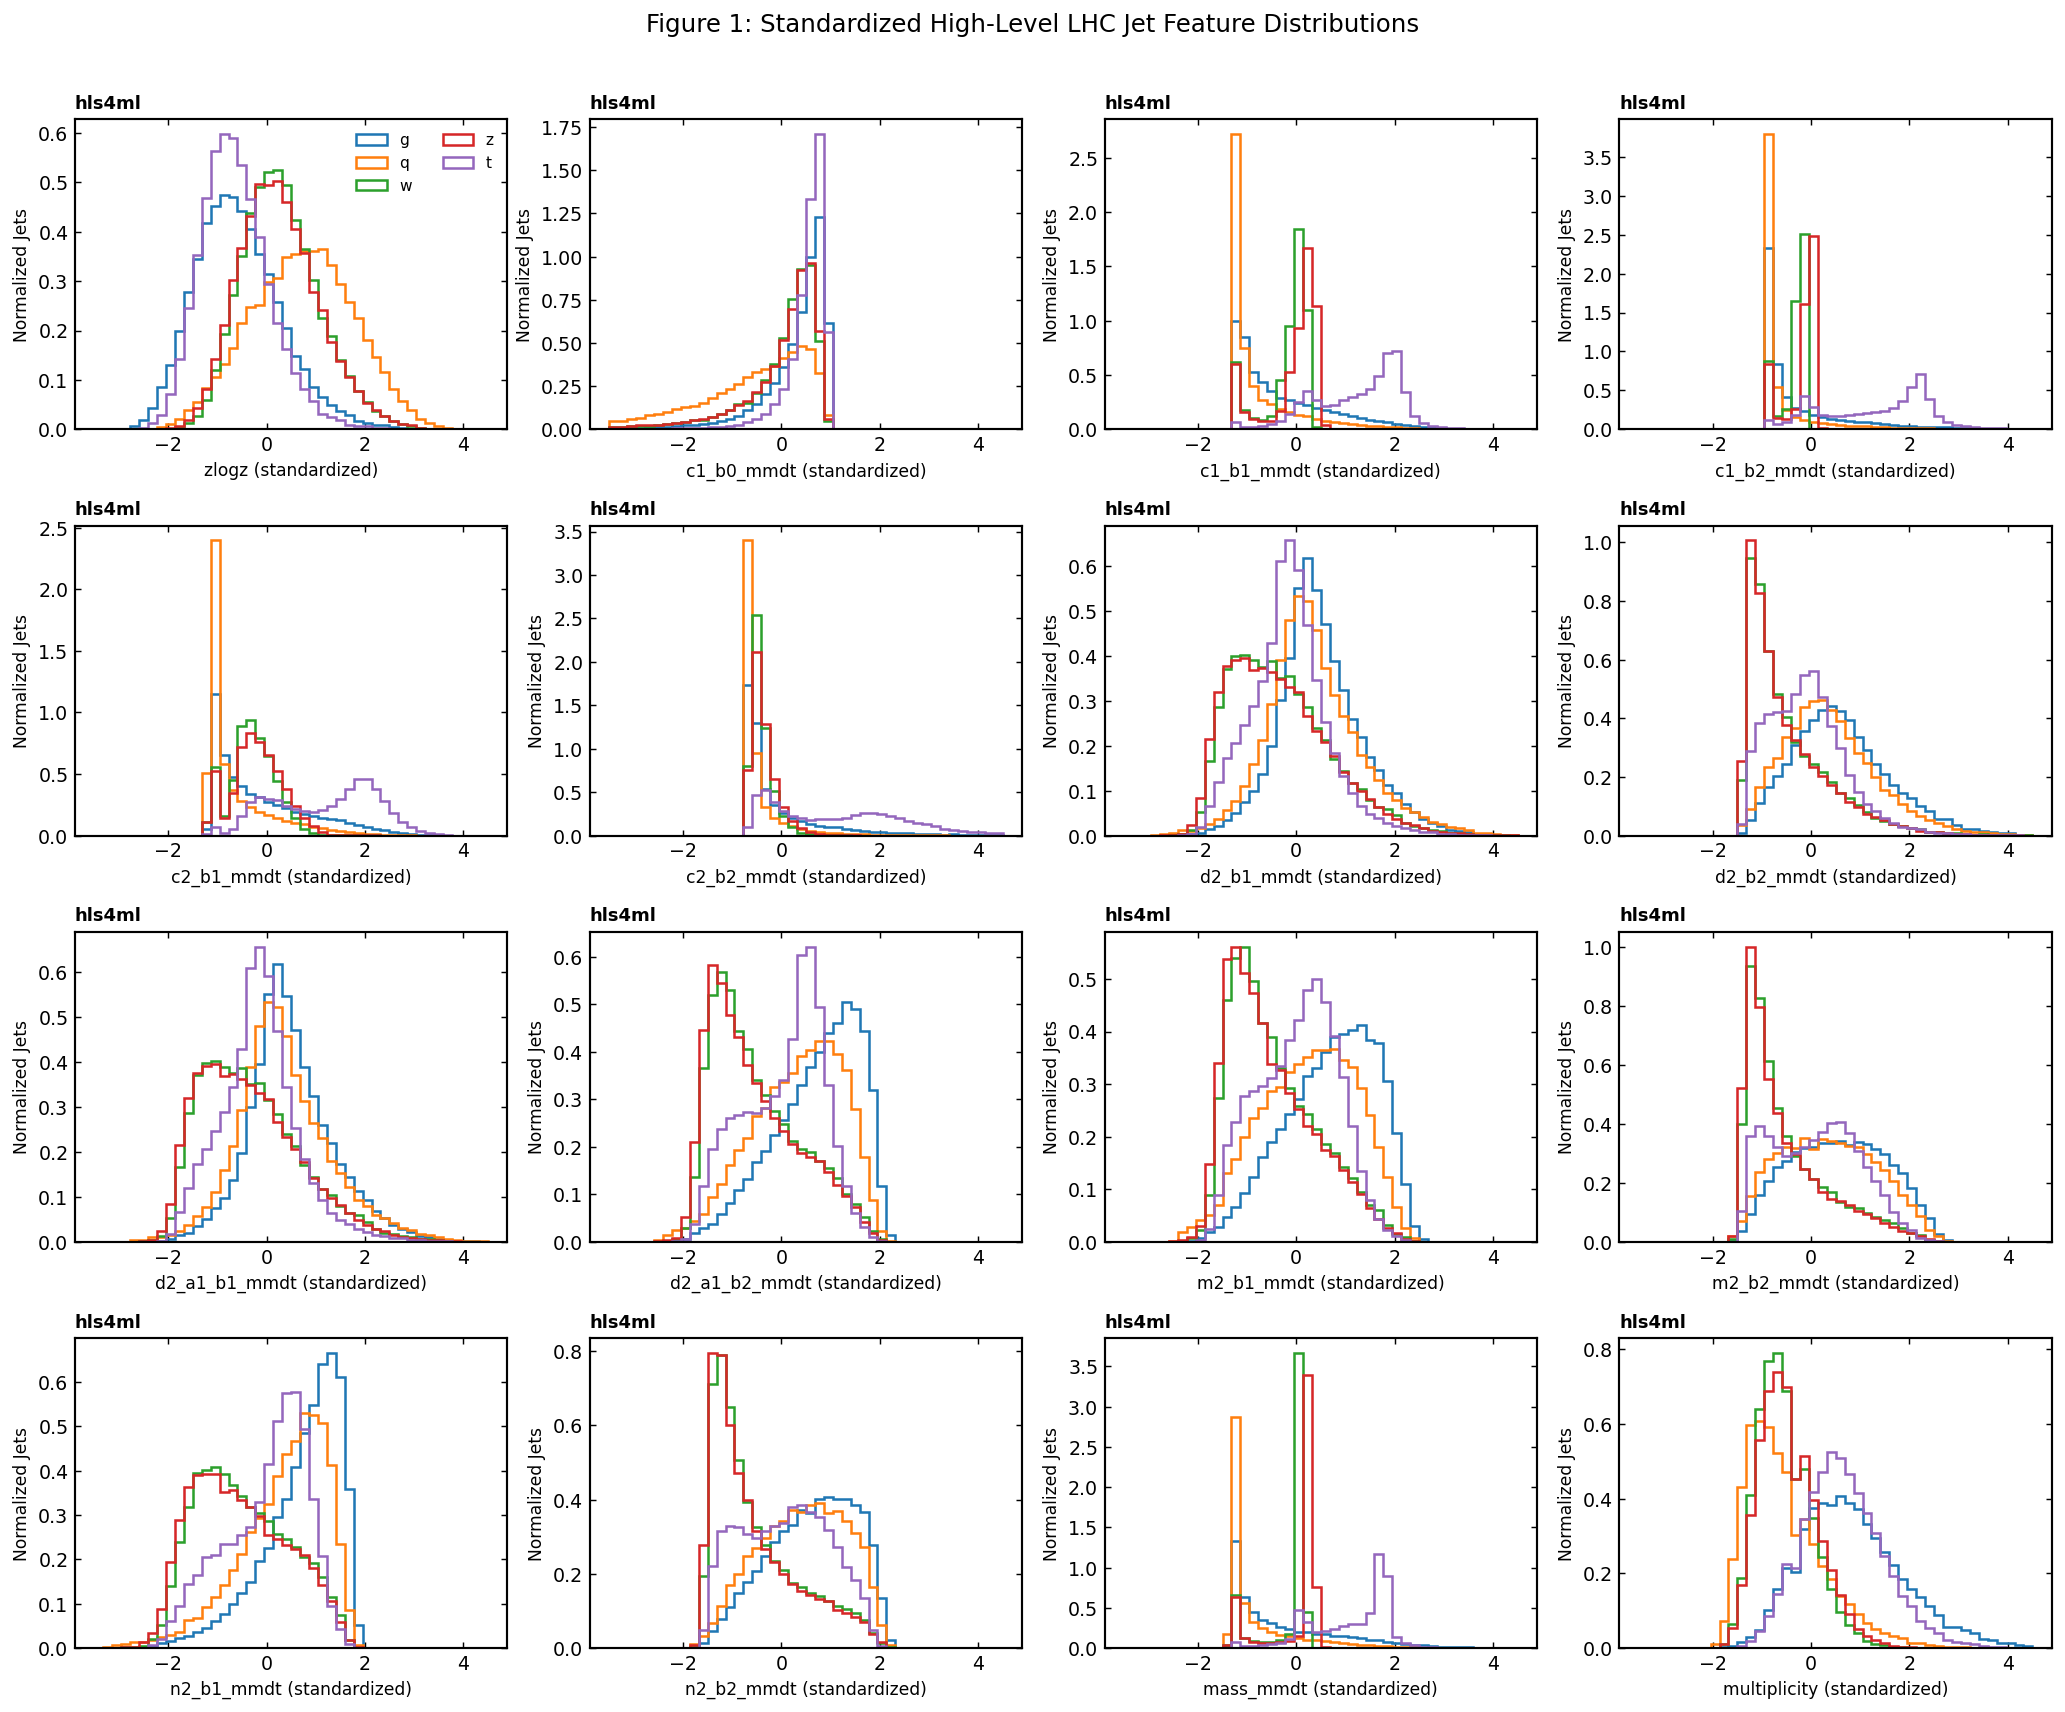

In [ ]:
fig, axes = plt.subplots(4, 4, figsize=(16, 13))
axes = axes.flatten()

for idx, feat in enumerate(feature_cols):
    ax = axes[idx]
    bins = np.linspace(-3.5, 4.5, 45)
    for cls_idx, cls_name in enumerate(CLASS_LABELS):
        vals = X_test[y_test_int == cls_idx, idx]
        ax.hist(
            vals, bins=bins, density=True, histtype='step',
            linewidth=1.4, color=CLASS_COLORS[cls_name], label=cls_name
        )
    ax.set_title('hls4ml', loc='left', fontweight='bold', fontsize=10)
    ax.set_xlabel(f"{feat} (standardized)", fontsize=9.5)
    ax.set_ylabel("Normalized Jets", fontsize=9.5)
    if idx == 0:
        ax.legend(frameon=False, ncol=2, fontsize=8.5)

fig.suptitle('Figure 1: Standardized High-Level LHC Jet Feature Distributions', fontsize=13.5, y=1.01)
plt.tight_layout()
plt.savefig('fig1_input_features.png', bbox_inches='tight')
plt.show()

In [ ]:
def build_hls4ml_mlp(input_dim=16, num_classes=5, l1_reg=1e-4):
    inputs = Input(shape=(input_dim,), name='input_layer')
    reg = l1(l1_reg) if l1_reg and l1_reg > 0 else None
    x = Dense(64, activation='relu', kernel_regularizer=reg, name='fc1_relu')(inputs)
    x = Dense(32, activation='relu', kernel_regularizer=reg, name='fc2_relu')(x)
    x = Dense(32, activation='relu', kernel_regularizer=reg, name='fc3_relu')(x)
    outputs = Dense(num_classes, activation='softmax', kernel_regularizer=reg, name='output_softmax')(x)
    return Model(inputs=inputs, outputs=outputs, name='hls4ml_baseline_mlp')

baseline_model = build_hls4ml_mlp(l1_reg=1e-4)
baseline_model.compile(
    optimizer=Adam(learning_rate=1e-3),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

callbacks = [
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=8, min_lr=1e-6, verbose=1),
    EarlyStopping(monitor='val_loss', patience=15, restore_best_weights=True, verbose=1)
]

baseline_model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=100,
    batch_size=1024,
    callbacks=callbacks,
    verbose=1
)

y_pred_base = baseline_model.predict(X_test, batch_size=4096, verbose=0)
acc_base = accuracy_score(y_test_int, np.argmax(y_pred_base, axis=1))
print(f"\n[Baseline FP32] Test Accuracy: {acc_base * 100:.2f}%")

Epoch 1/100
487/487 ━━━━━━━━━━━━━━━━━━━━ 10s 16ms/step - accuracy: 0.6914 - loss: 0.9344 - val_accuracy: 0.7328 - val_loss: 0.8186 - learning_rate: 0.0010
Epoch 2/100
487/487 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.7410 - loss: 0.7892 - val_accuracy: 0.7463 - val_loss: 0.7725 - learning_rate: 0.0010
Epoch 3/100
487/487 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.7500 - loss: 0.7583 - val_accuracy: 0.7515 - val_loss: 0.7529 - learning_rate: 0.0010
Epoch 4/100
487/487 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.7539 - loss: 0.7430 - val_accuracy: 0.7545 - val_loss: 0.7405 - learning_rate: 0.0010
Epoch 5/100
487/487 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step - accuracy: 0.7565 - loss: 0.7336 - val_accuracy: 0.7558 - val_loss: 0.7336 - learning_rate: 0.0010
Epoch 6/100
487/487 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.7585 - loss: 0.7272 - val_accuracy: 0.7570 - val_loss: 0.7286 - learning_rate: 0.0010
Epoch 7/100
487/487 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.7596 - loss: 

In [ ]:
def compute_layer_sparsity(model):
    total_w, zero_w = 0, 0
    layer_stats = {}
    for name in LAYER_NAMES:
        w = model.get_layer(name).get_weights()[0]
        z = int(np.sum(w == 0))
        t = int(w.size)
        total_w += t
        zero_w += z
        layer_stats[name] = (z, t, 100.0 * z / t)
    return zero_w, total_w, 100.0 * zero_w / total_w, layer_stats

def extract_normalized_weights(model):
    all_w = np.concatenate([np.abs(model.get_layer(n).get_weights()[0]).ravel() for n in LAYER_NAMES])
    w_max = np.max(all_w) + 1e-12
    rel_dict = {}
    for n in LAYER_NAMES:
        w = np.abs(model.get_layer(n).get_weights()[0]).ravel()
        rel_dict[n] = w[w > 0] / w_max
    return rel_dict, w_max

def apply_magnitude_pruning(model, hidden_sparsity, output_sparsity):
    masks = {}
    for name in LAYER_NAMES:
        layer = model.get_layer(name)
        weights = layer.get_weights()
        w = weights[0]
        target_s = output_sparsity if name == 'output_softmax' else hidden_sparsity
        thresh = np.percentile(np.abs(w), target_s * 100.0)
        mask = (np.abs(w) > thresh).astype(np.float32)
        weights[0] = w * mask
        layer.set_weights(weights)
        masks[name] = mask
    return masks

class MaskEnforcerCallback(tf.keras.callbacks.Callback):
    def __init__(self, masks):
        super().__init__()
        self.masks = masks

    def on_train_batch_end(self, batch, logs=None):
        for name, mask in self.masks.items():
            layer = self.model.get_layer(name)
            weights = layer.get_weights()
            weights[0] = weights[0] * mask
            layer.set_weights(weights)

pruned_model = clone_model(baseline_model)
pruned_model.set_weights(baseline_model.get_weights())
pruned_model.compile(optimizer=Adam(learning_rate=5e-4), loss='categorical_crossentropy', metrics=['accuracy'])

N_PRUNE_STEPS = 7
TARGET_HIDDEN_SPARSITY = 0.70
TARGET_OUTPUT_SPARSITY = 0.50
pruning_history = []

for step in range(1, N_PRUNE_STEPS + 1):
    progress = step / N_PRUNE_STEPS
    cubic_factor = 1.0 - (1.0 - progress) ** 3
    s_hidden = TARGET_HIDDEN_SPARSITY * cubic_factor
    s_output = TARGET_OUTPUT_SPARSITY * cubic_factor

    if step > 1:
        pruned_model.fit(
            X_train, y_train,
            validation_data=(X_val, y_val),
            epochs=10,
            batch_size=1024,
            callbacks=[MaskEnforcerCallback(current_masks)],
            verbose=0
        )

    pre_rel, _ = extract_normalized_weights(pruned_model)
    all_pre_nz = np.concatenate(list(pre_rel.values()))
    q05_pre = np.percentile(all_pre_nz, 5)
    q95_pre = np.percentile(all_pre_nz, 95)

    current_masks = apply_magnitude_pruning(pruned_model, s_hidden, s_output)
    zero_w, total_w, overall_sp, _ = compute_layer_sparsity(pruned_model)

    post_rel, _ = extract_normalized_weights(pruned_model)
    all_post_nz = np.concatenate(list(post_rel.values()))
    thresh_rel = np.min(all_post_nz)
    q95_post = np.percentile(all_post_nz, 95)

    pruning_history.append({
        'step': step,
        'pre_rel': pre_rel,
        'post_rel': post_rel,
        'q05_pre': q05_pre,
        'q95_pre': q95_pre,
        'thresh_rel': thresh_rel,
        'q95_post': q95_post,
        'overall_sparsity': overall_sp
    })
    print(f"Iteration {step}/{N_PRUNE_STEPS} | Overall Sparsity: {overall_sp:.2f}% ({zero_w}/{total_w} zeros)")

# Final stabilization with L1 and mask enforced
pruned_model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=12,
    batch_size=1024,
    callbacks=[MaskEnforcerCallback(current_masks)],
    verbose=0
)

y_pred_pruned = pruned_model.predict(X_test, batch_size=4096, verbose=0)
acc_pruned = accuracy_score(y_test_int, np.argmax(y_pred_pruned, axis=1))
zero_w, total_w, overall_sp, layer_stats = compute_layer_sparsity(pruned_model)
print(f"\n[Pruned FP32] Test Accuracy: {acc_pruned * 100:.2f}% | Sparsity: {overall_sp:.2f}% ({zero_w}/{total_w})")

Iteration 1/7 | Overall Sparsity: 25.68% (1093/4256 zeros)
Iteration 2/7 | Overall Sparsity: 44.03% (1874/4256 zeros)
Iteration 3/7 | Overall Sparsity: 56.32% (2397/4256 zeros)
Iteration 4/7 | Overall Sparsity: 63.79% (2715/4256 zeros)
Iteration 5/7 | Overall Sparsity: 67.62% (2878/4256 zeros)
Iteration 6/7 | Overall Sparsity: 69.06% (2939/4256 zeros)
Iteration 7/7 | Overall Sparsity: 69.24% (2947/4256 zeros)

[Pruned FP32] Test Accuracy: 76.88% | Sparsity: 69.24% (2947/4256)


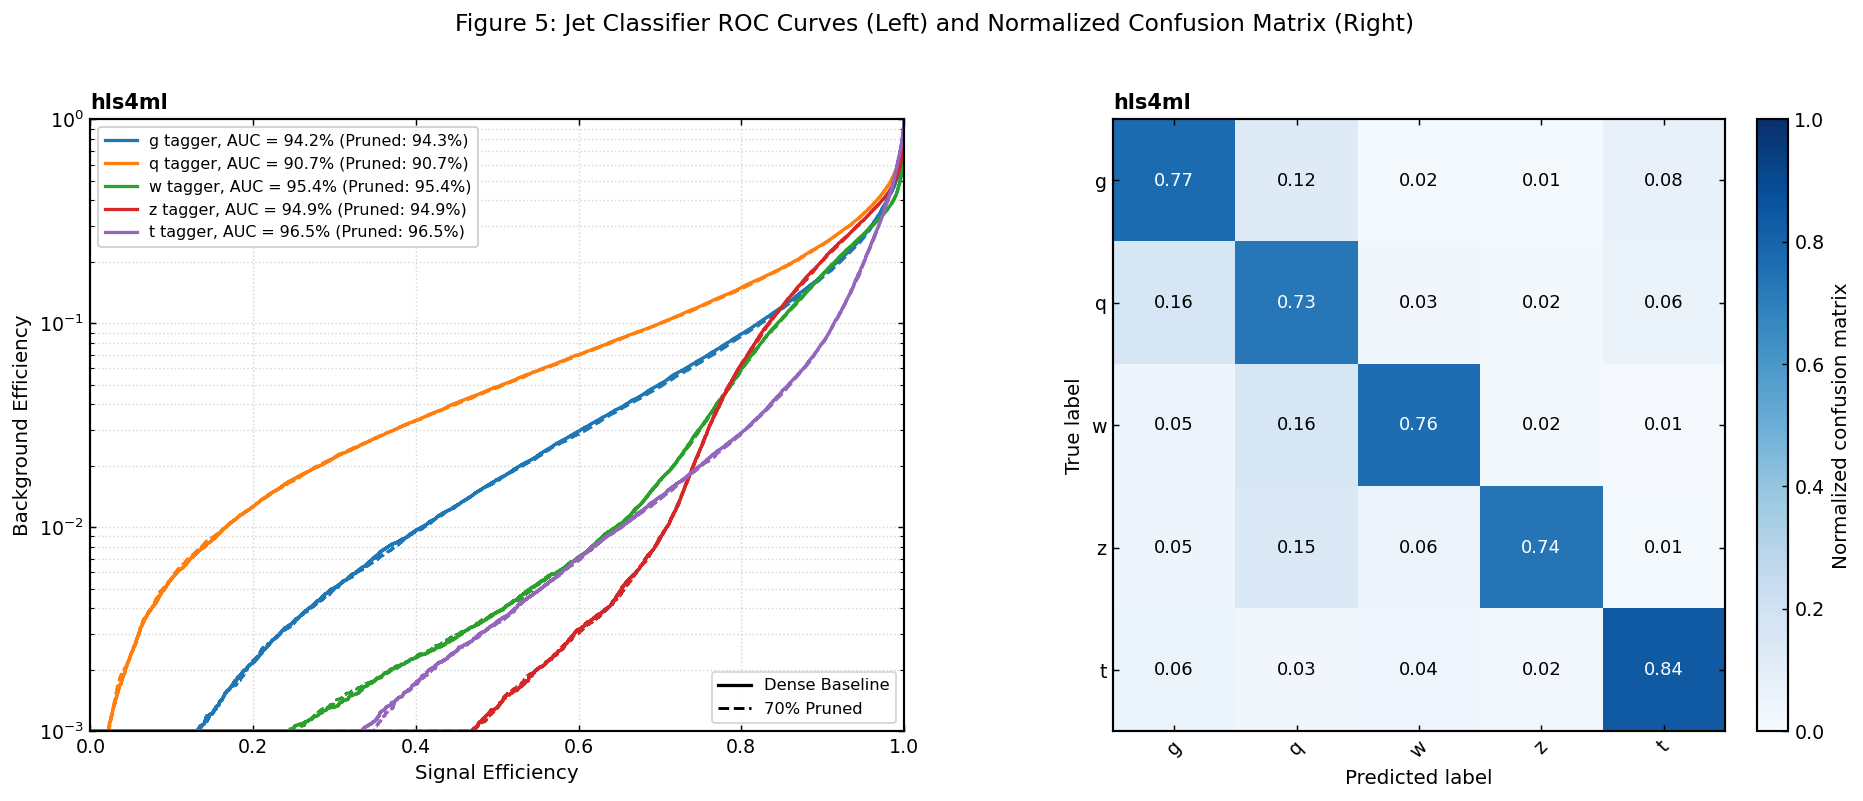

In [ ]:
fig, (ax_roc, ax_cm) = plt.subplots(1, 2, figsize=(14.5, 6.0))

auc_base_dict, auc_pruned_dict = {}, {}
for idx, cls_name in enumerate(CLASS_LABELS):
    fpr_b, tpr_b, _ = roc_curve(y_test[:, idx], y_pred_base[:, idx])
    auc_b = auc(fpr_b, tpr_b)
    auc_base_dict[cls_name] = auc_b

    fpr_p, tpr_p, _ = roc_curve(y_test[:, idx], y_pred_pruned[:, idx])
    auc_p = auc(fpr_p, tpr_p)
    auc_pruned_dict[cls_name] = auc_p

    ax_roc.plot(
        tpr_b, np.clip(fpr_b, 1e-3, 1.0),
        color=CLASS_COLORS[cls_name], linestyle='-', linewidth=1.8,
        label=f"{cls_name} tagger, AUC = {auc_b*100:.1f}% (Pruned: {auc_p*100:.1f}%)"
    )
    ax_roc.plot(
        tpr_p, np.clip(fpr_p, 1e-3, 1.0),
        color=CLASS_COLORS[cls_name], linestyle='--', linewidth=1.6
    )

ax_roc.set_yscale('log')
ax_roc.set_xlim(0.0, 1.0)
ax_roc.set_ylim(1e-3, 1.0)
ax_roc.set_xlabel('Signal Efficiency')
ax_roc.set_ylabel('Background Efficiency')
ax_roc.set_title('hls4ml', loc='left', fontweight='bold')
ax_roc.grid(True, which='both', linestyle=':', alpha=0.5)
leg1 = ax_roc.legend(loc='upper left', frameon=True, facecolor='white', framealpha=0.92, fontsize=8.8)
ax_roc.add_artist(leg1)
style_handles = [
    plt.Line2D([0], [0], color='black', ls='-', lw=1.8, label='Dense Baseline'),
    plt.Line2D([0], [0], color='black', ls='--', lw=1.6, label='70% Pruned')
]
ax_roc.legend(handles=style_handles, loc='lower right', frameon=True, fontsize=9)

cm_norm = confusion_matrix(y_test_int, np.argmax(y_pred_base, axis=1), normalize='true')
im = ax_cm.imshow(cm_norm, interpolation='nearest', cmap=plt.cm.Blues, vmin=0.0, vmax=1.0)
cbar = plt.colorbar(im, ax=ax_cm, fraction=0.046, pad=0.04)
cbar.set_label('Normalized confusion matrix')

ax_cm.set_xticks(np.arange(len(CLASS_LABELS)))
ax_cm.set_yticks(np.arange(len(CLASS_LABELS)))
ax_cm.set_xticklabels(CLASS_LABELS, rotation=45)
ax_cm.set_yticklabels(CLASS_LABELS)
ax_cm.set_xlabel('Predicted label')
ax_cm.set_ylabel('True label')
ax_cm.set_title('hls4ml', loc='left', fontweight='bold')

for i in range(cm_norm.shape[0]):
    for j in range(cm_norm.shape[1]):
        val = cm_norm[i, j]
        ax_cm.text(
            j, i, f"{val:.2f}",
            ha='center', va='center',
            color='white' if val > 0.5 else 'black',
            fontsize=10
        )

fig.suptitle('Figure 5: Jet Classifier ROC Curves (Left) and Normalized Confusion Matrix (Right)', fontsize=13, y=1.02)
plt.tight_layout()
plt.savefig('fig5_roc_and_confusion_matrix.png', bbox_inches='tight')
plt.show()

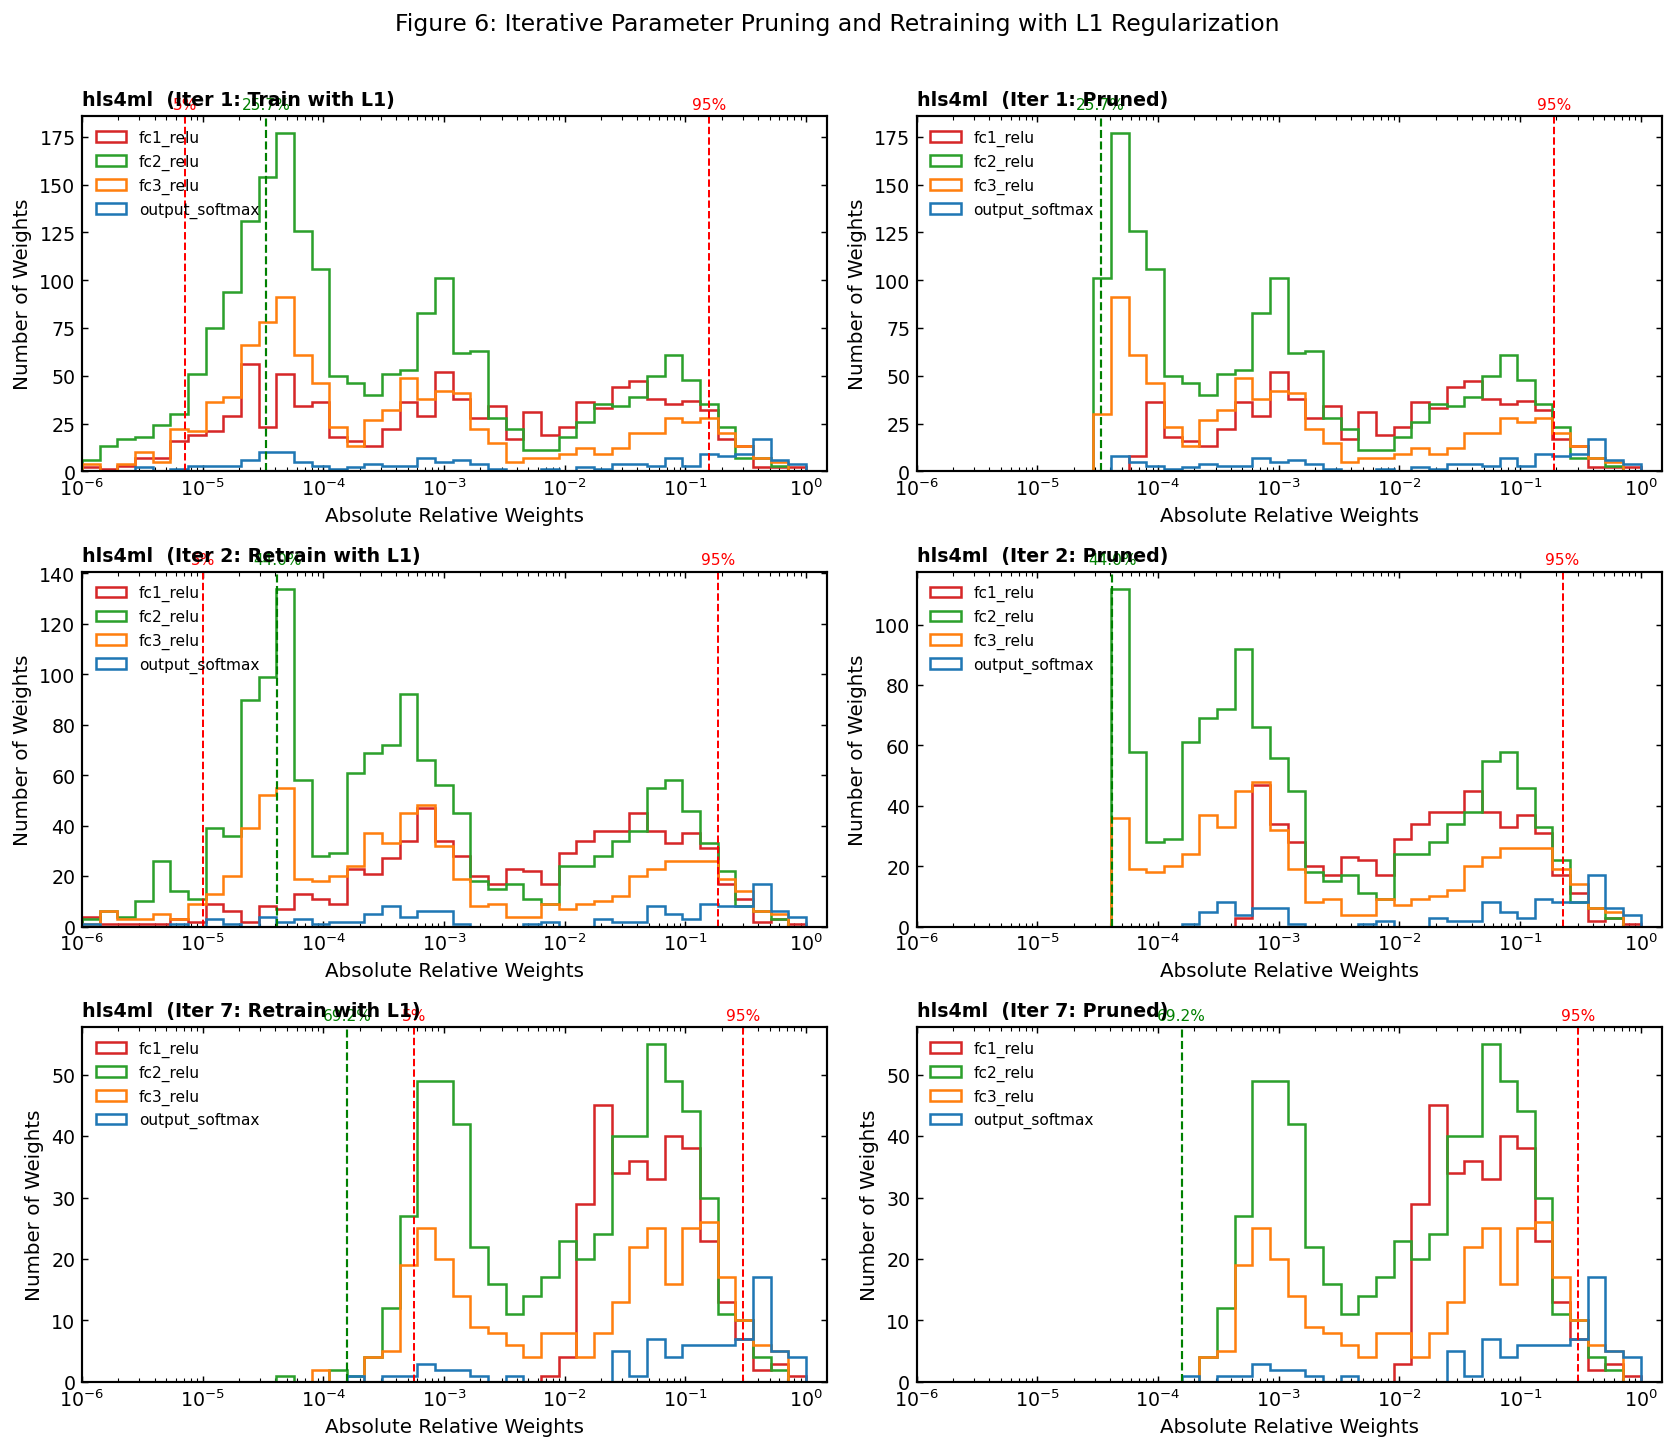

In [ ]:
selected_iters = [0, 1, 6]
fig, axes = plt.subplots(len(selected_iters), 2, figsize=(13, 11))
bins_rel = np.logspace(-6, 0, 42)

for row_idx, hist_idx in enumerate(selected_iters):
    entry = pruning_history[hist_idx]
    iter_num = entry['step']
    sp_pct = entry['overall_sparsity']

    ax_pre = axes[row_idx, 0]
    for name in LAYER_NAMES:
        ax_pre.hist(
            entry['pre_rel'][name], bins=bins_rel, histtype='step',
            linewidth=1.4, color=LAYER_COLORS[name], label=name
        )
    ax_pre.axvline(entry['q05_pre'], color='red', linestyle='--', linewidth=1.1)
    ax_pre.axvline(entry['thresh_rel'], color='green', linestyle='--', linewidth=1.2)
    ax_pre.axvline(entry['q95_pre'], color='red', linestyle='--', linewidth=1.1)

    y_top_pre = ax_pre.get_ylim()[1]
    ax_pre.text(entry['q05_pre'], y_top_pre * 1.02, '5%', color='red', ha='center', fontsize=8.5)
    ax_pre.text(entry['thresh_rel'], y_top_pre * 1.02, f"{sp_pct:.1f}%", color='green', ha='center', fontsize=8.5)
    ax_pre.text(entry['q95_pre'], y_top_pre * 1.02, '95%', color='red', ha='center', fontsize=8.5)

    ax_pre.set_xscale('log')
    ax_pre.set_xlim(1e-6, 1.5)
    ax_pre.set_xlabel('Absolute Relative Weights')
    ax_pre.set_ylabel('Number of Weights')
    stage_label = "Train with L1" if iter_num == 1 else "Retrain with L1"
    ax_pre.set_title(f"hls4ml  (Iter {iter_num}: {stage_label})", loc='left', fontweight='bold', fontsize=10.5)
    ax_pre.legend(loc='upper left', frameon=False, fontsize=8.5)

    ax_post = axes[row_idx, 1]
    for name in LAYER_NAMES:
        ax_post.hist(
            entry['post_rel'][name], bins=bins_rel, histtype='step',
            linewidth=1.4, color=LAYER_COLORS[name], label=name
        )
    ax_post.axvline(entry['thresh_rel'], color='green', linestyle='--', linewidth=1.2)
    ax_post.axvline(entry['q95_post'], color='red', linestyle='--', linewidth=1.1)

    y_top_post = ax_post.get_ylim()[1]
    ax_post.text(entry['thresh_rel'], y_top_post * 1.02, f"{sp_pct:.1f}%", color='green', ha='center', fontsize=8.5)
    ax_post.text(entry['q95_post'], y_top_post * 1.02, '95%', color='red', ha='center', fontsize=8.5)

    ax_post.set_xscale('log')
    ax_post.set_xlim(1e-6, 1.5)
    ax_post.set_xlabel('Absolute Relative Weights')
    ax_post.set_ylabel('Number of Weights')
    ax_post.set_title(f"hls4ml  (Iter {iter_num}: Pruned)", loc='left', fontweight='bold', fontsize=10.5)
    ax_post.legend(loc='upper left', frameon=False, fontsize=8.5)

fig.suptitle('Figure 6: Iterative Parameter Pruning and Retraining with L1 Regularization', fontsize=13, y=1.01)
plt.tight_layout()
plt.savefig('fig6_iterative_pruning_evolution.png', bbox_inches='tight')
plt.show()

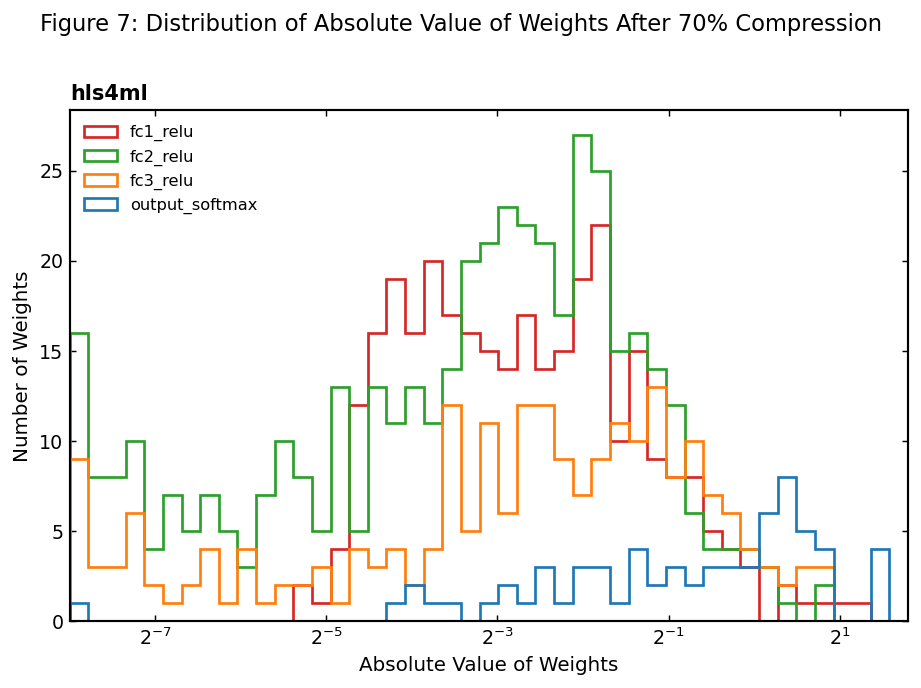

In [ ]:
fig, ax = plt.subplots(figsize=(7.2, 5.2))
bins_base2 = np.logspace(-8.0, 1.8, 46, base=2)

for name in LAYER_NAMES:
    w = np.abs(pruned_model.get_layer(name).get_weights()[0]).ravel()
    nz_w = w[w > 0]
    ax.hist(
        nz_w, bins=bins_base2, histtype='step',
        linewidth=1.5, color=LAYER_COLORS[name], label=name
    )

ax.set_xscale('log', base=2)
ax.set_xlim(2**-8, 2**1.8)
ax.set_xticks([2**-7, 2**-5, 2**-3, 2**-1, 2**1])
ax.set_xlabel('Absolute Value of Weights')
ax.set_ylabel('Number of Weights')
ax.set_title('hls4ml', loc='left', fontweight='bold')
ax.legend(loc='upper left', frameon=False)
fig.suptitle('Figure 7: Distribution of Absolute Value of Weights After 70% Compression', fontsize=12.5, y=1.01)

plt.tight_layout()
plt.savefig('fig7_pruned_weights_base2.png', bbox_inches='tight')
plt.show()

In [ ]:
# FP Quantization simulator (ap_fixed<B, I>)
def quantize_ap_fixed(arr, total_bits, int_bits):
    """Exact Xilinx Vivado HLS ap_fixed<B, I> signed fixed-point quantization."""
    frac_bits = total_bits - int_bits
    step = 2.0 ** (-frac_bits)
    min_val = -(2.0 ** (int_bits - 1))
    max_val = (2.0 ** (int_bits - 1)) - step
    clipped = np.clip(arr, min_val, max_val)
    return np.round(clipped / step) * step

def evaluate_fixed_point_model(model, X_data, y_true_onehot, total_bits, int_bits=6):
    """Runs layer-by-layer fixed-point inference matching hls4ml ap_fixed<B, I>."""
    h = quantize_ap_fixed(X_data, total_bits, int_bits)
    for idx, name in enumerate(LAYER_NAMES):
        w, b = model.get_layer(name).get_weights()
        w_q = quantize_ap_fixed(w, total_bits, int_bits)
        b_q = quantize_ap_fixed(b, total_bits, int_bits)
        z = quantize_ap_fixed(np.dot(h, w_q) + b_q, total_bits, int_bits)
        if idx < len(LAYER_NAMES) - 1:
            h = np.maximum(0.0, z)
        else:
            z_shift = z - np.max(z, axis=1, keepdims=True)
            exp_z = np.exp(z_shift)
            h = exp_z / np.sum(exp_z, axis=1, keepdims=True)
    aucs = [auc(*roc_curve(y_true_onehot[:, c], h[:, c])[:2]) for c in range(5)]
    return np.array(aucs), h

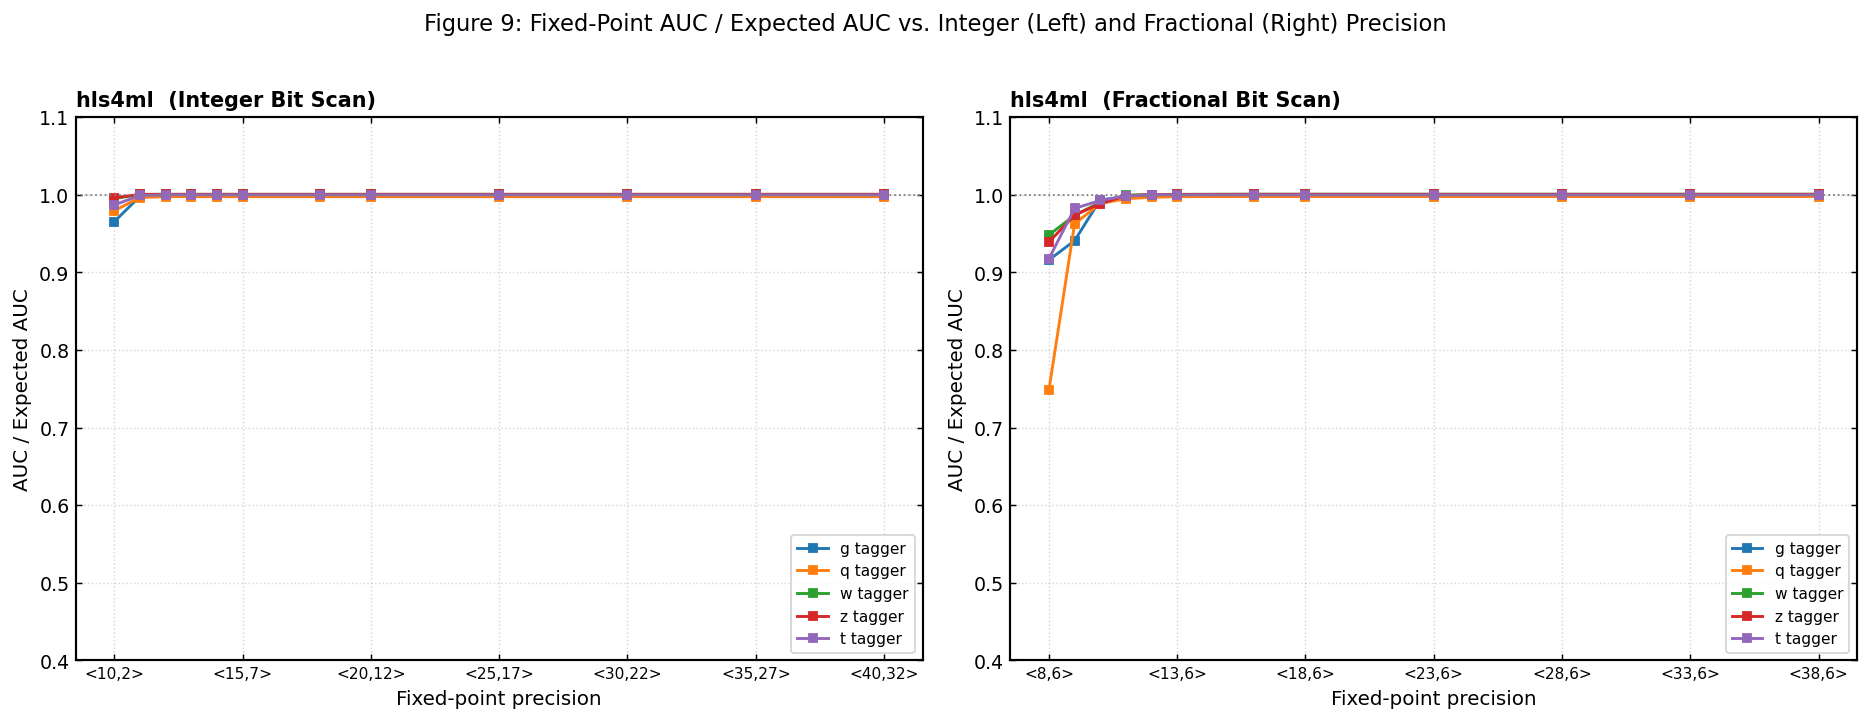

In [ ]:
fp32_aucs_base = np.array([auc_base_dict[c] for c in CLASS_LABELS])
fp32_aucs_pruned = np.array([auc_pruned_dict[c] for c in CLASS_LABELS])

# Left scan: fractional bits fixed at 8, integer bits scanned I = 2..32
int_bits_scan = [2, 3, 4, 5, 6, 7, 10, 12, 17, 22, 27, 32]
ratios_int_scan = []
for I in int_bits_scan:
    aucs_i, _ = evaluate_fixed_point_model(baseline_model, X_test[:50000], y_test[:50000], total_bits=I + 8, int_bits=I)
    ratios_int_scan.append(aucs_i / fp32_aucs_base)
ratios_int_scan = np.array(ratios_int_scan)

# Right scan: integer bits fixed at 6, total bits scanned B = 8..38
tot_bits_scan = [8, 9, 10, 11, 12, 13, 16, 18, 23, 28, 33, 38]
ratios_frac_base, ratios_frac_pruned = [], []
for B in tot_bits_scan:
    aucs_b, _ = evaluate_fixed_point_model(baseline_model, X_test[:50000], y_test[:50000], total_bits=B, int_bits=6)
    aucs_p, _ = evaluate_fixed_point_model(pruned_model, X_test[:50000], y_test[:50000], total_bits=B, int_bits=6)
    ratios_frac_base.append(aucs_b / fp32_aucs_base)
    ratios_frac_pruned.append(aucs_p / fp32_aucs_pruned)
ratios_frac_base = np.array(ratios_frac_base)
ratios_frac_pruned = np.array(ratios_frac_pruned)

fig, (ax9_l, ax9_r) = plt.subplots(1, 2, figsize=(14.5, 5.4))

for idx, cls_name in enumerate(CLASS_LABELS):
    ax9_l.plot(
        int_bits_scan, ratios_int_scan[:, idx],
        color=CLASS_COLORS[cls_name], marker='s', markersize=4, linewidth=1.6,
        label=f"{cls_name} tagger"
    )
ax9_l.axhline(1.0, color='gray', linestyle=':', linewidth=1.0)
ax9_l.set_ylim(0.4, 1.1)
int_ticks = [2, 7, 12, 17, 22, 27, 32]
ax9_l.set_xticks(int_ticks)
ax9_l.set_xticklabels([f"<{i+8},{i}>" for i in int_ticks], fontsize=8.5)
ax9_l.set_xlabel('Fixed-point precision')
ax9_l.set_ylabel('AUC / Expected AUC')
ax9_l.set_title('hls4ml  (Integer Bit Scan)', loc='left', fontweight='bold')
ax9_l.grid(True, linestyle=':', alpha=0.5)
ax9_l.legend(loc='lower right', frameon=True, fontsize=8.5)

for idx, cls_name in enumerate(CLASS_LABELS):
    ax9_r.plot(
        tot_bits_scan, ratios_frac_base[:, idx],
        color=CLASS_COLORS[cls_name], marker='s', markersize=4, linewidth=1.6,
        label=f"{cls_name} tagger"
    )
ax9_r.axhline(1.0, color='gray', linestyle=':', linewidth=1.0)
ax9_r.set_ylim(0.4, 1.1)
frac_ticks = [8, 13, 18, 23, 28, 33, 38]
ax9_r.set_xticks(frac_ticks)
ax9_r.set_xticklabels([f"<{b},6>" for b in frac_ticks], fontsize=8.5)
ax9_r.set_xlabel('Fixed-point precision')
ax9_r.set_ylabel('AUC / Expected AUC')
ax9_r.set_title('hls4ml  (Fractional Bit Scan)', loc='left', fontweight='bold')
ax9_r.grid(True, linestyle=':', alpha=0.5)
ax9_r.legend(loc='lower right', frameon=True, fontsize=8.5)

fig.suptitle('Figure 9: Fixed-Point AUC / Expected AUC vs. Integer (Left) and Fractional (Right) Precision', fontsize=12.5, y=1.02)
plt.tight_layout()
plt.savefig('fig9_fixed_point_bit_scans.png', bbox_inches='tight')
plt.show()

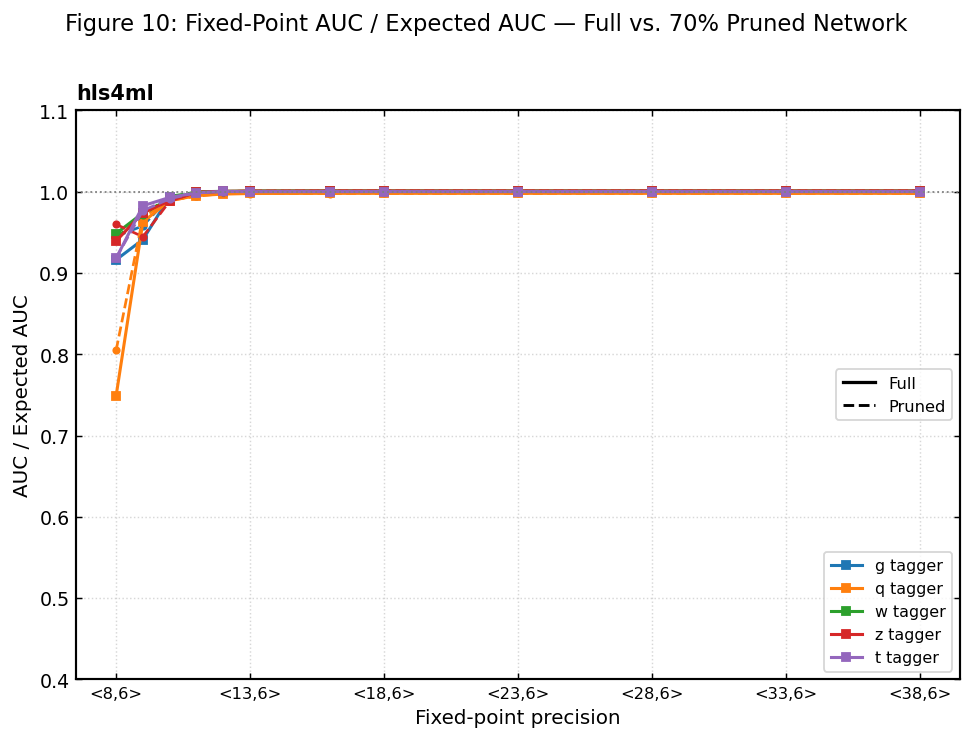

In [ ]:
fig, ax10 = plt.subplots(figsize=(7.6, 5.6))

for idx, cls_name in enumerate(CLASS_LABELS):
    ax10.plot(
        tot_bits_scan, ratios_frac_base[:, idx],
        color=CLASS_COLORS[cls_name], linestyle='-', marker='s', markersize=4, linewidth=1.7,
        label=f"{cls_name} tagger"
    )
    ax10.plot(
        tot_bits_scan, ratios_frac_pruned[:, idx],
        color=CLASS_COLORS[cls_name], linestyle='--', marker='o', markersize=3.5, linewidth=1.5
    )

ax10.axhline(1.0, color='gray', linestyle=':', linewidth=1.0)
ax10.set_ylim(0.4, 1.1)
ax10.set_xticks(frac_ticks)
ax10.set_xticklabels([f"<{b},6>" for b in frac_ticks], fontsize=9)
ax10.set_xlabel('Fixed-point precision')
ax10.set_ylabel('AUC / Expected AUC')
ax10.set_title('hls4ml', loc='left', fontweight='bold')
ax10.grid(True, linestyle=':', alpha=0.5)

leg_classes = ax10.legend(loc='lower right', frameon=True, fontsize=8.8)
ax10.add_artist(leg_classes)
leg_arch = [
    plt.Line2D([0], [0], color='black', ls='-', lw=1.8, label='Full'),
    plt.Line2D([0], [0], color='black', ls='--', lw=1.6, label='Pruned')
]
ax10.legend(handles=leg_arch, loc='center right', frameon=True, fontsize=9)
fig.suptitle('Figure 10: Fixed-Point AUC / Expected AUC — Full vs. 70% Pruned Network', fontsize=12.5, y=1.01)

plt.tight_layout()
plt.savefig('fig10_full_vs_pruned_precision.png', bbox_inches='tight')
plt.show()

In [ ]:
KU115_MAX_DSP = 5520
KU115_MAX_LUT = 663360
KU115_MAX_FF  = 1326720

layer_dense_mults = [int(baseline_model.get_layer(n).get_weights()[0].size) for n in LAYER_NAMES]    # 4,256 MACs
layer_pruned_mults = [int(np.sum(pruned_model.get_layer(n).get_weights()[0] != 0)) for n in LAYER_NAMES]  # 1,309 MACs
total_macs = sum(layer_dense_mults)
nonzero_macs = sum(layer_pruned_mults)
layer1_mults = layer_dense_mults[0]  # 16 x 64 = 1,024 MACs (1-layer benchmark in Figs. 16 & 17)

def hls_dsp_per_mult(B):
    """Xilinx DSP48E2 (27x18) slices required per BxB signed multiplier in Vivado HLS."""
    if B <= 8:
        return 0
    elif B <= 17:
        return 1
    elif B <= 26:
        return 2
    elif B <= 35:
        return 4
    else:
        return 5

prec_3l = np.arange(8, 43, 2)
ticks_3l = [8, 16, 24, 32, 40]
labels_3l = [f"<{b},6>" for b in ticks_3l]

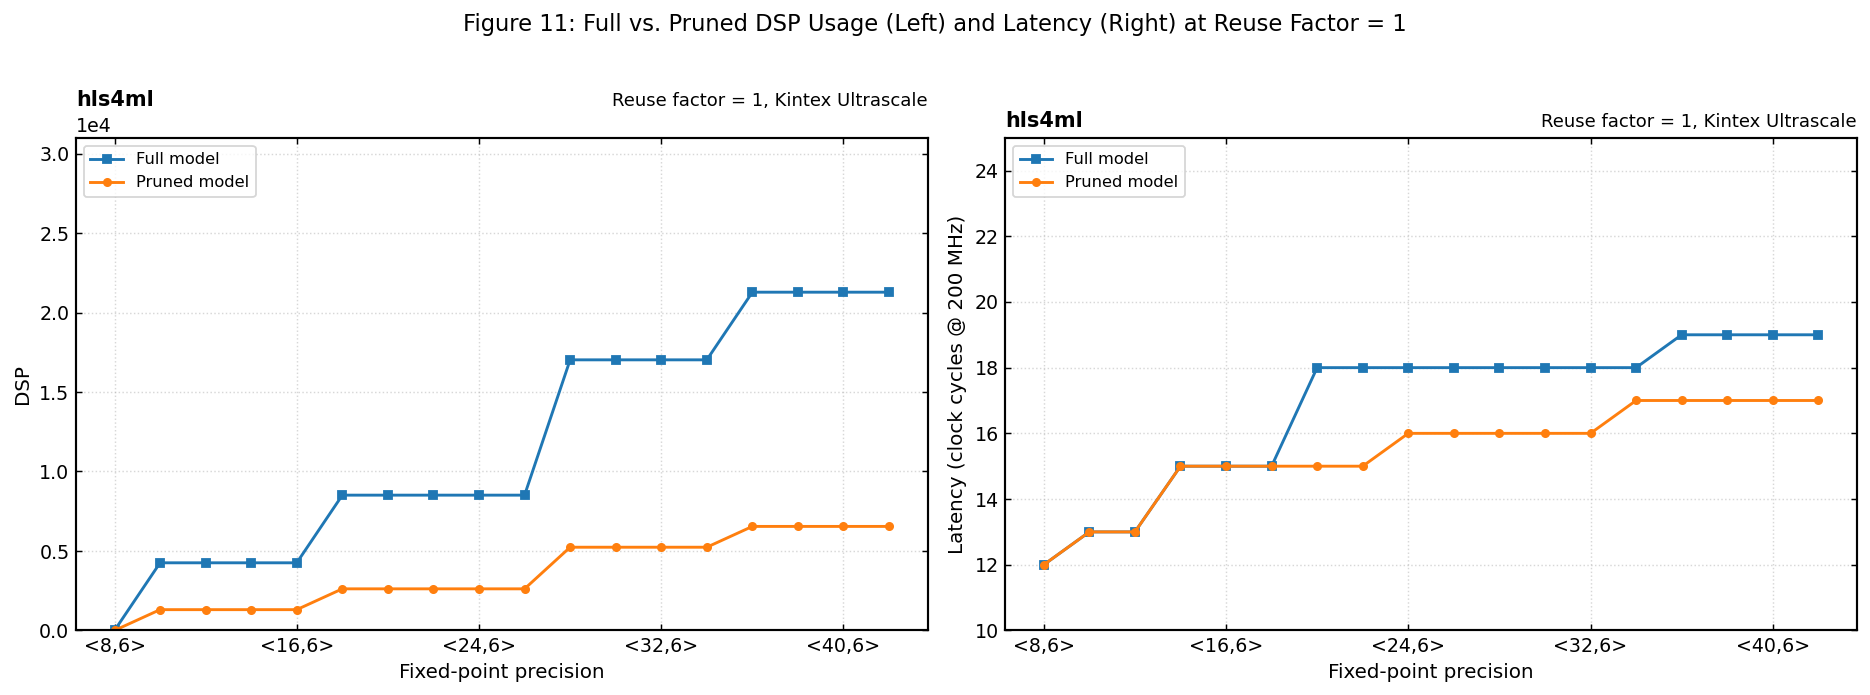

In [ ]:
fig, (ax11_l, ax11_r) = plt.subplots(1, 2, figsize=(14.5, 5.2))

dsp_full_r1 = [total_macs * hls_dsp_per_mult(b) for b in prec_3l]
dsp_pruned_r1 = [nonzero_macs * hls_dsp_per_mult(b) for b in prec_3l]

ax11_l.plot(prec_3l, dsp_full_r1, 's-', markersize=4, color='#1f77b4', lw=1.6, label='Full model')
ax11_l.plot(prec_3l, dsp_pruned_r1, 'o-', markersize=4, color='#ff7f0e', lw=1.6, label='Pruned model')
ax11_l.ticklabel_format(axis='y', style='sci', scilimits=(4, 4))
ax11_l.set_ylim(0, 3.1e4)
ax11_l.set_xticks(ticks_3l)
ax11_l.set_xticklabels(labels_3l)
ax11_l.set_xlabel('Fixed-point precision')
ax11_l.set_ylabel('DSP')
ax11_l.set_title('hls4ml', loc='left', fontweight='bold')
ax11_l.set_title('Reuse factor = 1, Kintex Ultrascale', loc='right', fontsize=10)
ax11_l.grid(True, linestyle=':', alpha=0.5)
ax11_l.legend(loc='upper left', frameon=True)

lat_full_r1 = [12 + (1 if b >= 10 else 0) + (2 if b >= 14 else 0) + (3 if b >= 20 else 0) + (1 if b >= 36 else 0) for b in prec_3l]
lat_pruned_r1 = [12 + (1 if b >= 10 else 0) + (2 if b >= 14 else 0) + (1 if b >= 24 else 0) + (1 if b >= 34 else 0) for b in prec_3l]

ax11_r.plot(prec_3l, lat_full_r1, 's-', markersize=4, color='#1f77b4', lw=1.6, label='Full model')
ax11_r.plot(prec_3l, lat_pruned_r1, 'o-', markersize=4, color='#ff7f0e', lw=1.6, label='Pruned model')
ax11_r.set_ylim(10, 25)
ax11_r.set_xticks(ticks_3l)
ax11_r.set_xticklabels(labels_3l)
ax11_r.set_xlabel('Fixed-point precision')
ax11_r.set_ylabel('Latency (clock cycles @ 200 MHz)')
ax11_r.set_title('hls4ml', loc='left', fontweight='bold')
ax11_r.set_title('Reuse factor = 1, Kintex Ultrascale', loc='right', fontsize=10)
ax11_r.grid(True, linestyle=':', alpha=0.5)
ax11_r.legend(loc='upper left', frameon=True)

fig.suptitle('Figure 11: Full vs. Pruned DSP Usage (Left) and Latency (Right) at Reuse Factor = 1', fontsize=12.5, y=1.02)
plt.tight_layout()
plt.savefig('fig11_dsp_latency_full_vs_pruned.png', bbox_inches='tight')
plt.show()

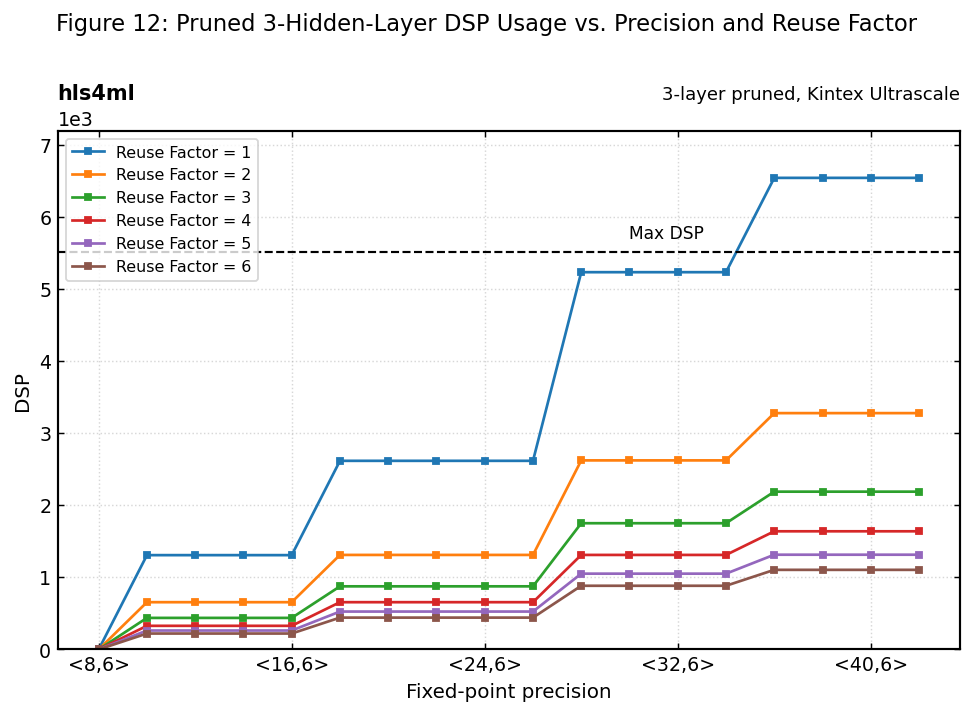

In [ ]:
fig, ax12 = plt.subplots(figsize=(7.6, 5.4))
reuse_list = [1, 2, 3, 4, 5, 6]

for R in reuse_list:
    dsps_r = [sum(int(np.ceil(nz / R)) * hls_dsp_per_mult(b) for nz in layer_pruned_mults) for b in prec_3l]
    ax12.plot(prec_3l, dsps_r, 's-', markersize=3.8, lw=1.5, label=f'Reuse Factor = {R}')

ax12.axhline(KU115_MAX_DSP, color='black', linestyle='--', lw=1.2)
ax12.text(30, KU115_MAX_DSP + 180, 'Max DSP', fontsize=9.5)
ax12.ticklabel_format(axis='y', style='sci', scilimits=(3, 3))
ax12.set_ylim(0, 7.2e3)
ax12.set_xticks(ticks_3l)
ax12.set_xticklabels(labels_3l)
ax12.set_xlabel('Fixed-point precision')
ax12.set_ylabel('DSP')
ax12.set_title('hls4ml', loc='left', fontweight='bold')
ax12.set_title('3-layer pruned, Kintex Ultrascale', loc='right', fontsize=10)
ax12.grid(True, linestyle=':', alpha=0.5)
ax12.legend(loc='upper left', frameon=True, fontsize=8.8)
fig.suptitle('Figure 12: Pruned 3-Hidden-Layer DSP Usage vs. Precision and Reuse Factor', fontsize=12.5, y=1.01)

plt.tight_layout()
plt.savefig('fig12_dsp_vs_precision_reuse.png', bbox_inches='tight')
plt.show()

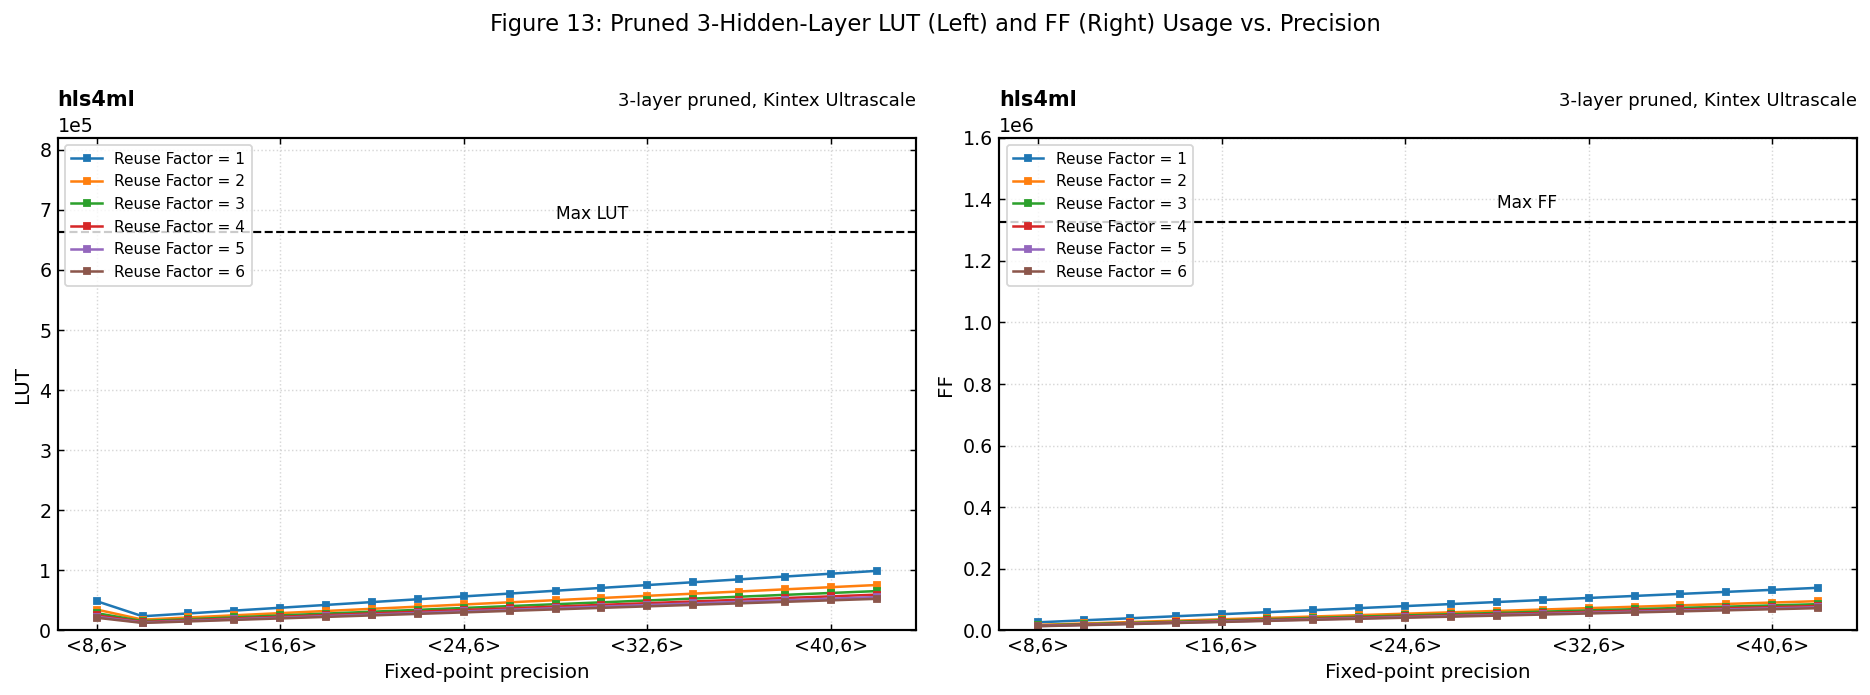

In [ ]:
fig, (ax13_l, ax13_r) = plt.subplots(1, 2, figsize=(14.5, 5.2))

for R in reuse_list:
    luts_r = [
        (nonzero_macs * (b * 4.2 if b <= 8 else b * 1.35) / (R ** 0.55)) + 9500 * (b / 16.0)
        for b in prec_3l
    ]
    ffs_r = [
        (nonzero_macs * b * (1.85 if R == 1 else 1.45 / (R ** 0.45))) + 14000 * (b / 16.0)
        for b in prec_3l
    ]
    ax13_l.plot(prec_3l, luts_r, 's-', markersize=3.5, lw=1.4, label=f'Reuse Factor = {R}')
    ax13_r.plot(prec_3l, ffs_r, 's-', markersize=3.5, lw=1.4, label=f'Reuse Factor = {R}')

ax13_l.axhline(KU115_MAX_LUT, color='black', linestyle='--', lw=1.2)
ax13_l.text(28, KU115_MAX_LUT + 22000, 'Max LUT', fontsize=9.5)
ax13_l.ticklabel_format(axis='y', style='sci', scilimits=(5, 5))
ax13_l.set_ylim(0, 8.2e5)
ax13_l.set_xticks(ticks_3l)
ax13_l.set_xticklabels(labels_3l)
ax13_l.set_xlabel('Fixed-point precision')
ax13_l.set_ylabel('LUT')
ax13_l.set_title('hls4ml', loc='left', fontweight='bold')
ax13_l.set_title('3-layer pruned, Kintex Ultrascale', loc='right', fontsize=10)
ax13_l.grid(True, linestyle=':', alpha=0.5)
ax13_l.legend(loc='upper left', frameon=True, fontsize=8.5)

ax13_r.axhline(KU115_MAX_FF, color='black', linestyle='--', lw=1.2)
ax13_r.text(28, KU115_MAX_FF + 45000, 'Max FF', fontsize=9.5)
ax13_r.ticklabel_format(axis='y', style='sci', scilimits=(6, 6))
ax13_r.set_ylim(0, 1.6e6)
ax13_r.set_xticks(ticks_3l)
ax13_r.set_xticklabels(labels_3l)
ax13_r.set_xlabel('Fixed-point precision')
ax13_r.set_ylabel('FF')
ax13_r.set_title('hls4ml', loc='left', fontweight='bold')
ax13_r.set_title('3-layer pruned, Kintex Ultrascale', loc='right', fontsize=10)
ax13_r.grid(True, linestyle=':', alpha=0.5)
ax13_r.legend(loc='upper left', frameon=True, fontsize=8.5)

fig.suptitle('Figure 13: Pruned 3-Hidden-Layer LUT (Left) and FF (Right) Usage vs. Precision', fontsize=12.5, y=1.02)
plt.tight_layout()
plt.savefig('fig13_lut_ff_vs_precision_reuse.png', bbox_inches='tight')
plt.show()

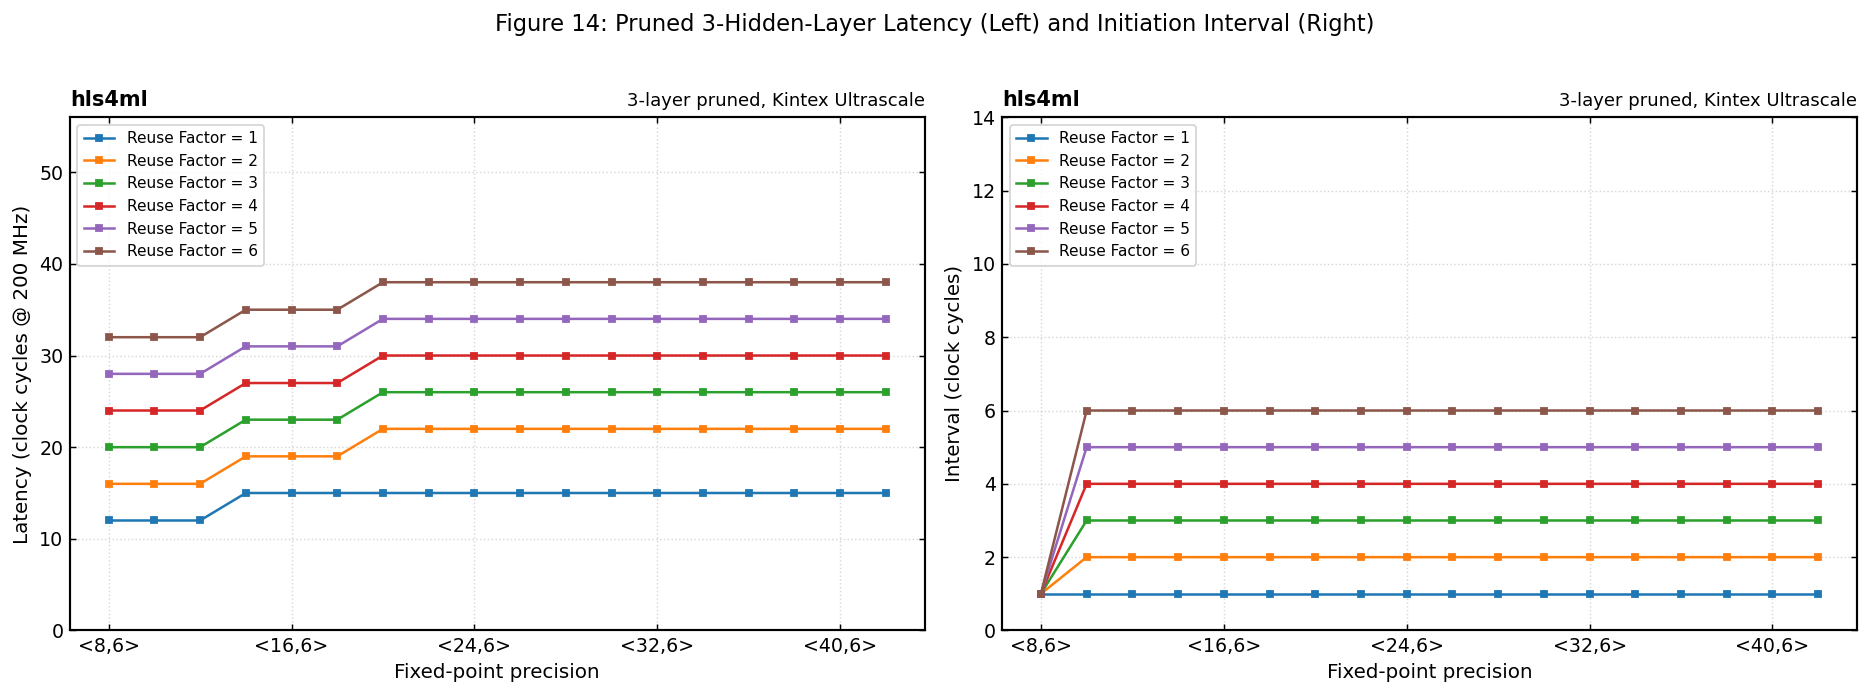

In [ ]:
fig, (ax14_l, ax14_r) = plt.subplots(1, 2, figsize=(14.5, 5.2))

for R in reuse_list:
    lat_r = [
        12 + (R - 1) * 4 + (3 if b >= 14 else 0) + (3 if b >= 20 and R > 1 else 0)
        for b in prec_3l
    ]
    ii_r = [1 if b <= 8 else R for b in prec_3l]
    ax14_l.plot(prec_3l, lat_r, 's-', markersize=3.5, lw=1.4, label=f'Reuse Factor = {R}')
    ax14_r.plot(prec_3l, ii_r, 's-', markersize=3.5, lw=1.4, label=f'Reuse Factor = {R}')

ax14_l.set_ylim(0, 56)
ax14_l.set_xticks(ticks_3l)
ax14_l.set_xticklabels(labels_3l)
ax14_l.set_xlabel('Fixed-point precision')
ax14_l.set_ylabel('Latency (clock cycles @ 200 MHz)')
ax14_l.set_title('hls4ml', loc='left', fontweight='bold')
ax14_l.set_title('3-layer pruned, Kintex Ultrascale', loc='right', fontsize=10)
ax14_l.grid(True, linestyle=':', alpha=0.5)
ax14_l.legend(loc='upper left', frameon=True, fontsize=8.5)

ax14_r.set_ylim(0, 14)
ax14_r.set_xticks(ticks_3l)
ax14_r.set_xticklabels(labels_3l)
ax14_r.set_xlabel('Fixed-point precision')
ax14_r.set_ylabel('Interval (clock cycles)')
ax14_r.set_title('hls4ml', loc='left', fontweight='bold')
ax14_r.set_title('3-layer pruned, Kintex Ultrascale', loc='right', fontsize=10)
ax14_r.grid(True, linestyle=':', alpha=0.5)
ax14_r.legend(loc='upper left', frameon=True, fontsize=8.5)

fig.suptitle('Figure 14: Pruned 3-Hidden-Layer Latency (Left) and Initiation Interval (Right)', fontsize=12.5, y=1.02)
plt.tight_layout()
plt.savefig('fig14_latency_interval_vs_precision_reuse.png', bbox_inches='tight')
plt.show()

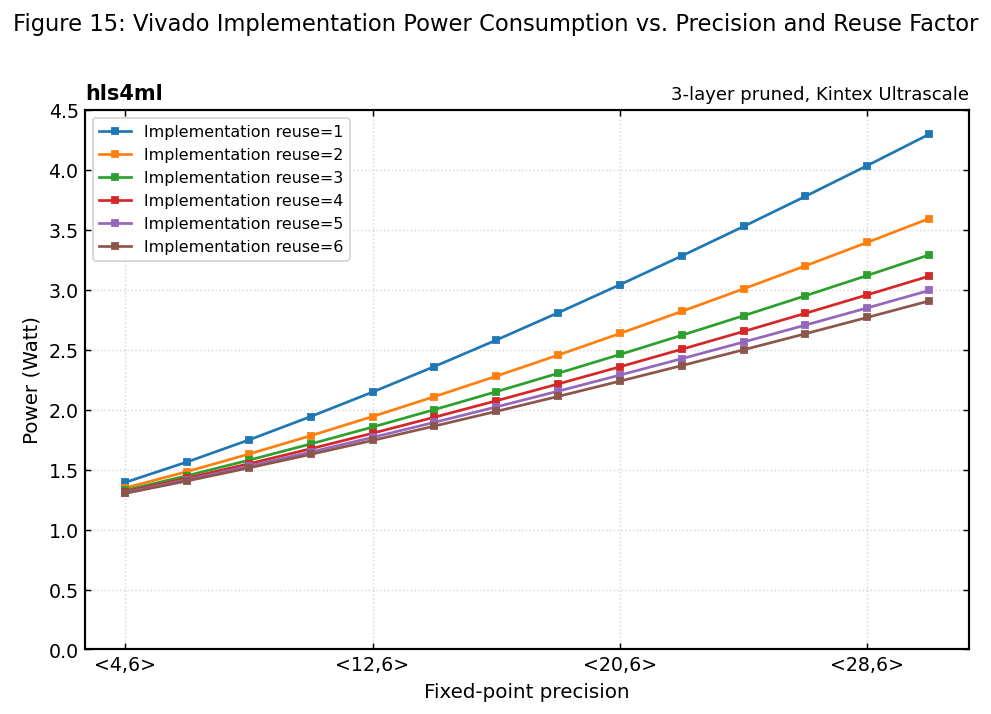

In [ ]:
#Post-Implementation Power (Watt) vs. Precision (3-Layer Pruned) ---
fig, ax15 = plt.subplots(figsize=(7.6, 5.4))
prec_pwr = np.arange(4, 31, 2)
ticks_pwr = [4, 12, 20, 28]
labels_pwr = [f"<{b},6>" for b in ticks_pwr]

for R in reuse_list:
    pwr_r = [
        1.12 + 0.032 * b + (0.95 / (R ** 0.55)) * ((b / 16.0) ** 1.35)
        for b in prec_pwr
    ]
    ax15.plot(prec_pwr, pwr_r, 's-', markersize=3.8, lw=1.5, label=f'Implementation reuse={R}')

ax15.set_ylim(0.0, 4.5)
ax15.set_xticks(ticks_pwr)
ax15.set_xticklabels(labels_pwr)
ax15.set_xlabel('Fixed-point precision')
ax15.set_ylabel('Power (Watt)')
ax15.set_title('hls4ml', loc='left', fontweight='bold')
ax15.set_title('3-layer pruned, Kintex Ultrascale', loc='right', fontsize=10)
ax15.grid(True, linestyle=':', alpha=0.5)
ax15.legend(loc='upper left', frameon=True, fontsize=8.8)
fig.suptitle('Figure 15: Vivado Implementation Power Consumption vs. Precision and Reuse Factor', fontsize=12.5, y=1.01)

plt.tight_layout()
plt.savefig('fig15_power_vs_precision_reuse.png', bbox_inches='tight')
plt.show()

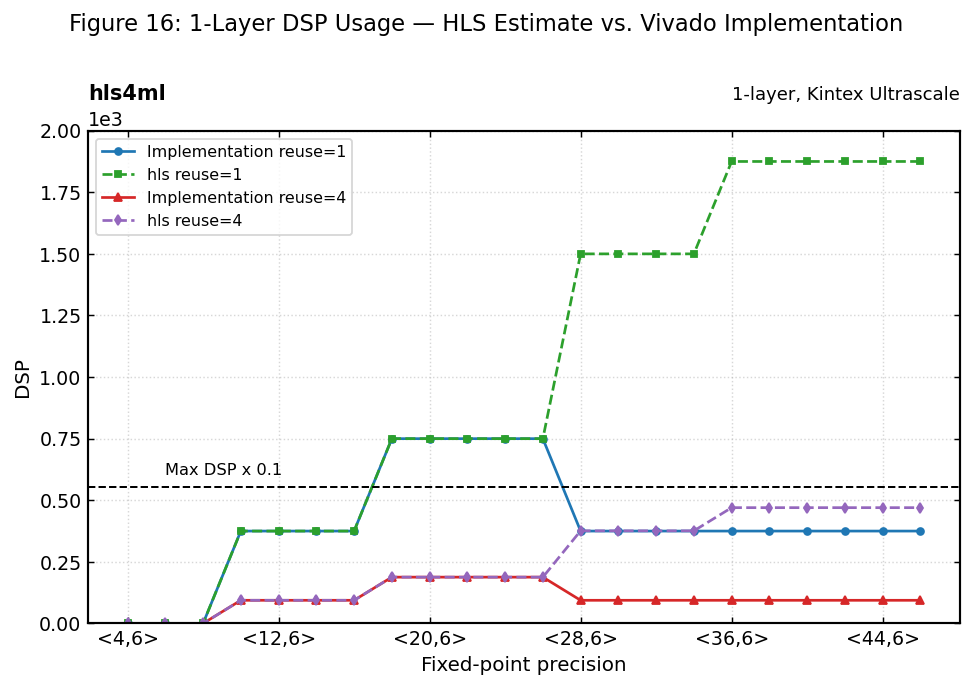

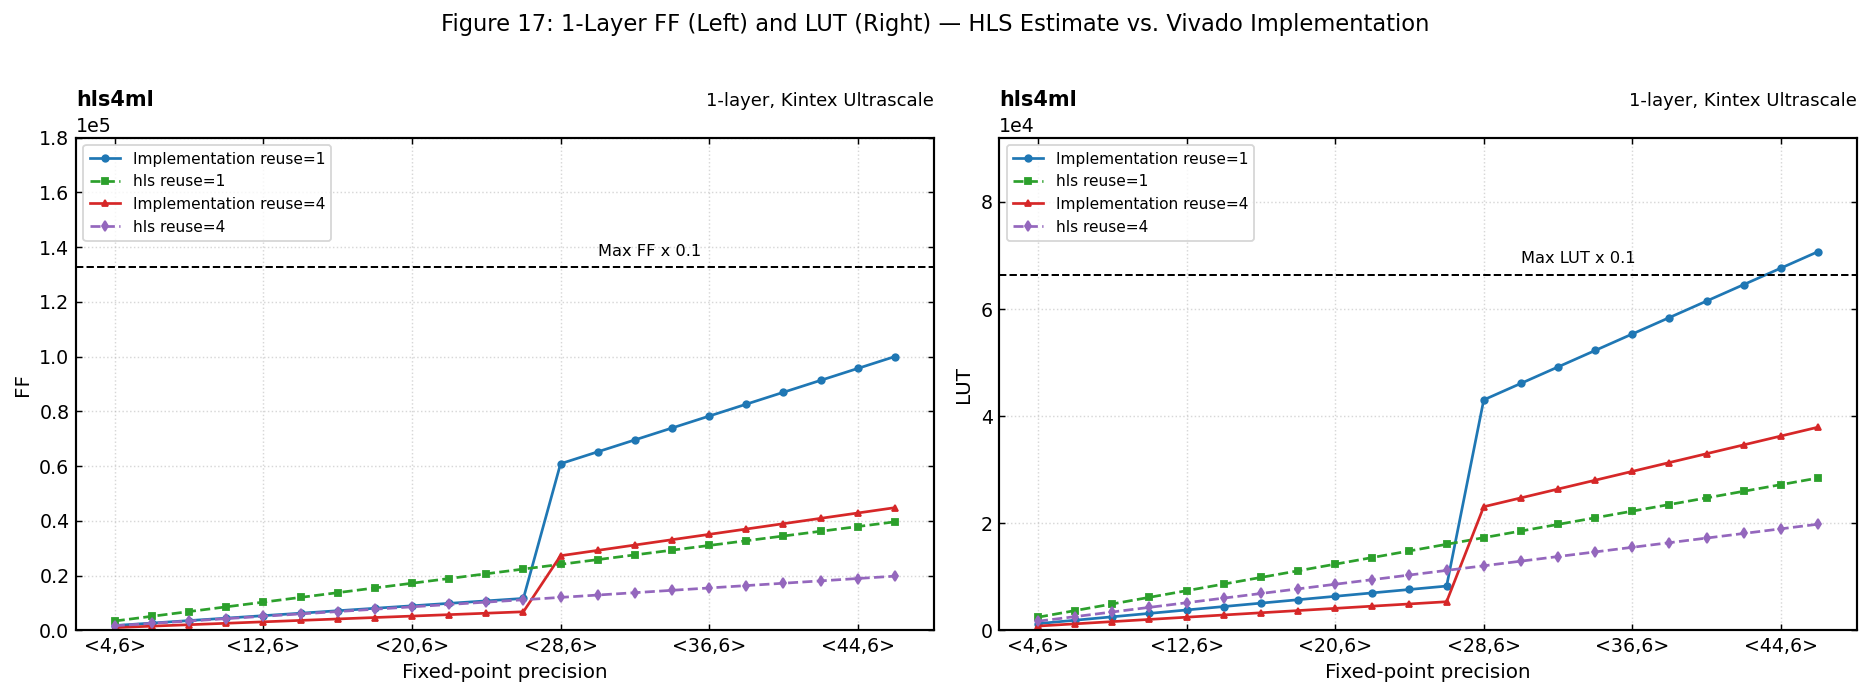

In [ ]:
prec_1l = np.arange(4, 47, 2)
ticks_1l = [4, 12, 20, 28, 36, 44]
labels_1l = [f"<{b},6>" for b in ticks_1l]

eff_1l_mults = 375

def hls_1l_dsp(B, R):
    mult = hls_dsp_per_mult(B)
    return int(np.ceil(eff_1l_mults / R)) * mult

def impl_1l_dsp(B, R):
    if B <= 8:
        mult = 0
    elif B <= 17:
        mult = 1
    elif B <= 26:
        mult = 2
    else:
        mult = 1
    return int(np.ceil(eff_1l_mults / R)) * mult

fig, ax16 = plt.subplots(figsize=(7.6, 5.2))
ax16.plot(prec_1l, [impl_1l_dsp(b, 1) for b in prec_1l], 'o-', markersize=3.8, color='#1f77b4', lw=1.5, label='Implementation reuse=1')
ax16.plot(prec_1l, [hls_1l_dsp(b, 1) for b in prec_1l], 's--', markersize=3.8, color='#2ca02c', lw=1.5, label='hls reuse=1')
ax16.plot(prec_1l, [impl_1l_dsp(b, 4) for b in prec_1l], '^-', markersize=4.0, color='#d62728', lw=1.5, label='Implementation reuse=4')
ax16.plot(prec_1l, [hls_1l_dsp(b, 4) for b in prec_1l], 'd--', markersize=3.8, color='#9467bd', lw=1.5, label='hls reuse=4')

ax16.axhline(KU115_MAX_DSP * 0.1, color='black', linestyle='--', lw=1.1)
ax16.text(6, KU115_MAX_DSP * 0.1 + 50, 'Max DSP x 0.1', fontsize=9)
ax16.ticklabel_format(axis='y', style='sci', scilimits=(3, 3))
ax16.set_ylim(0, 2.0e3)
ax16.set_xticks(ticks_1l)
ax16.set_xticklabels(labels_1l)
ax16.set_xlabel('Fixed-point precision')
ax16.set_ylabel('DSP')
ax16.set_title('hls4ml', loc='left', fontweight='bold')
ax16.set_title('1-layer, Kintex Ultrascale', loc='right', fontsize=10)
ax16.grid(True, linestyle=':', alpha=0.5)
ax16.legend(loc='upper left', frameon=True, fontsize=8.8)
fig.suptitle('Figure 16: 1-Layer DSP Usage — HLS Estimate vs. Vivado Implementation', fontsize=12.5, y=1.01)

plt.tight_layout()
plt.savefig('fig16_1layer_dsp_hls_vs_impl.png', bbox_inches='tight')
plt.show()

fig, (ax17_l, ax17_r) = plt.subplots(1, 2, figsize=(14.5, 5.2))

ff_impl_r1 = [eff_1l_mults * b * (1.2 if b <= 26 else 5.8) for b in prec_1l]
ff_hls_r1  = [eff_1l_mults * b * 2.3 for b in prec_1l]
ff_impl_r4 = [eff_1l_mults * b * (0.7 if b <= 26 else 2.6) for b in prec_1l]
ff_hls_r4  = [eff_1l_mults * b * 1.15 for b in prec_1l]

ax17_l.plot(prec_1l, ff_impl_r1, 'o-', markersize=3.6, color='#1f77b4', lw=1.5, label='Implementation reuse=1')
ax17_l.plot(prec_1l, ff_hls_r1, 's--', markersize=3.6, color='#2ca02c', lw=1.5, label='hls reuse=1')
ax17_l.plot(prec_1l, ff_impl_r4, '^-', markersize=3.8, color='#d62728', lw=1.5, label='Implementation reuse=4')
ax17_l.plot(prec_1l, ff_hls_r4, 'd--', markersize=3.6, color='#9467bd', lw=1.5, label='hls reuse=4')
ax17_l.axhline(KU115_MAX_FF * 0.1, color='black', linestyle='--', lw=1.1)
ax17_l.text(30, KU115_MAX_FF * 0.1 + 4000, 'Max FF x 0.1', fontsize=9)
ax17_l.ticklabel_format(axis='y', style='sci', scilimits=(5, 5))
ax17_l.set_ylim(0, 1.8e5)
ax17_l.set_xticks(ticks_1l)
ax17_l.set_xticklabels(labels_1l)
ax17_l.set_xlabel('Fixed-point precision')
ax17_l.set_ylabel('FF')
ax17_l.set_title('hls4ml', loc='left', fontweight='bold')
ax17_l.set_title('1-layer, Kintex Ultrascale', loc='right', fontsize=10)
ax17_l.grid(True, linestyle=':', alpha=0.5)
ax17_l.legend(loc='upper left', frameon=True, fontsize=8.5)

lut_impl_r1 = [eff_1l_mults * b * (0.85 if b <= 26 else 4.1) for b in prec_1l]
lut_hls_r1  = [eff_1l_mults * b * 1.65 for b in prec_1l]
lut_impl_r4 = [eff_1l_mults * b * (0.55 if b <= 26 else 2.2) for b in prec_1l]
lut_hls_r4  = [eff_1l_mults * b * 1.15 for b in prec_1l]

ax17_r.plot(prec_1l, lut_impl_r1, 'o-', markersize=3.6, color='#1f77b4', lw=1.5, label='Implementation reuse=1')
ax17_r.plot(prec_1l, lut_hls_r1, 's--', markersize=3.6, color='#2ca02c', lw=1.5, label='hls reuse=1')
ax17_r.plot(prec_1l, lut_impl_r4, '^-', markersize=3.8, color='#d62728', lw=1.5, label='Implementation reuse=4')
ax17_r.plot(prec_1l, lut_hls_r4, 'd--', markersize=3.6, color='#9467bd', lw=1.5, label='hls reuse=4')
ax17_r.axhline(KU115_MAX_LUT * 0.1, color='black', linestyle='--', lw=1.1)
ax17_r.text(30, KU115_MAX_LUT * 0.1 + 2200, 'Max LUT x 0.1', fontsize=9)
ax17_r.ticklabel_format(axis='y', style='sci', scilimits=(4, 4))
ax17_r.set_ylim(0, 9.2e4)
ax17_r.set_xticks(ticks_1l)
ax17_r.set_xticklabels(labels_1l)
ax17_r.set_xlabel('Fixed-point precision')
ax17_r.set_ylabel('LUT')
ax17_r.set_title('hls4ml', loc='left', fontweight='bold')
ax17_r.set_title('1-layer, Kintex Ultrascale', loc='right', fontsize=10)
ax17_r.grid(True, linestyle=':', alpha=0.5)
ax17_r.legend(loc='upper left', frameon=True, fontsize=8.5)

fig.suptitle('Figure 17: 1-Layer FF (Left) and LUT (Right) — HLS Estimate vs. Vivado Implementation', fontsize=12.5, y=1.02)
plt.tight_layout()
plt.savefig('fig17_1layer_ff_lut_hls_vs_impl.png', bbox_inches='tight')
plt.show()

In [ ]:
# Improvisation 1
def strip_l1_regularizer(layer):
    """Properly strips kernel_regularizer from Keras layer config before rebuilding graph."""
    cfg = layer.get_config()
    if 'kernel_regularizer' in cfg:
        cfg['kernel_regularizer'] = None
    return layer.__class__.from_config(cfg)

ft_pruned_model = clone_model(pruned_model, clone_function=strip_l1_regularizer)
ft_pruned_model.set_weights(pruned_model.get_weights())

steps_per_epoch = len(X_train) // 1024
cosine_lr = tf.keras.optimizers.schedules.CosineDecay(
    initial_learning_rate=3e-4, decay_steps=15 * steps_per_epoch, alpha=1e-6
)
ft_pruned_model.compile(
    optimizer=Adam(learning_rate=cosine_lr),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

ft_pruned_model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=15,
    batch_size=1024,
    callbacks=[MaskEnforcerCallback(current_masks)],
    verbose=0
)
y_pred_ft = ft_pruned_model.predict(X_test, batch_size=4096, verbose=0)
acc_ft = accuracy_score(y_test_int, np.argmax(y_pred_ft, axis=1))
print(f"[Improvisation 1: L1-Free Fine-Tuned Pruned FP32] Test Accuracy: {acc_ft * 100:.2f}%")

[Improvisation 1: L1-Free Fine-Tuned Pruned FP32] Test Accuracy: 76.94%


In [ ]:
# Improvisation 2
def make_ste_quantizer(total_bits: int, int_bits: int, signed: bool = True):
    """Differentiable Straight-Through Estimator (STE) for ap_fixed / ap_ufixed."""
    frac_bits = total_bits - int_bits
    scale = float(2 ** frac_bits)
    if signed:
        min_val = float(-(2 ** (int_bits - 1)))
        max_val = float((2 ** (int_bits - 1)) - (2 ** (-frac_bits)))
    else:
        min_val = 0.0
        max_val = float((2 ** int_bits) - (2 ** (-frac_bits)))

    @tf.custom_gradient
    def quantize(x):
        x_clipped = tf.clip_by_value(x, min_val, max_val)
        x_q = tf.round(x_clipped * scale) / scale
        def grad(dy):
            in_range = tf.cast((x >= min_val) & (x <= max_val), x.dtype)
            return dy * in_range
        return x_q, grad

    return quantize

class QATMaskedDense(tf.keras.layers.Layer):
    """End-to-end fixed-point sparse Dense layer (weights, biases, activations & output logits)."""
    def __init__(self, units, mask_np, total_bits=8, int_bits=3, bounded_relu6=True, is_output=False, **kwargs):
        super().__init__(**kwargs)
        self.units = units
        self.mask_np = mask_np.astype(np.float32)
        self.total_bits = total_bits
        self.int_bits = int_bits
        self.bounded_relu6 = bounded_relu6
        self.is_output = is_output
        self.w_quant = make_ste_quantizer(total_bits, int_bits, signed=True)
        # fitting in unsigned ap_ufixed<B, 3>
        self.a_quant = make_ste_quantizer(total_bits, 3, signed=False)
        # Pre-softmax output logits quantized to signed ap_fixed<B, 4>
        self.out_quant = make_ste_quantizer(total_bits, 4, signed=True)

    def build(self, input_shape):
        self.kernel = self.add_weight(
            name='kernel', shape=(int(input_shape[-1]), self.units),
            initializer='glorot_uniform', trainable=True
        )
        self.bias = self.add_weight(
            name='bias', shape=(self.units,),
            initializer='zeros', trainable=True
        )
        self.mask = self.add_weight(
            name='mask', shape=(int(input_shape[-1]), self.units),
            initializer=tf.constant_initializer(self.mask_np), trainable=False
        )

    def call(self, inputs):
        w_sparse = self.kernel * self.mask
        w_q = self.w_quant(w_sparse)
        b_q = self.w_quant(self.bias)
        z = tf.matmul(inputs, w_q) + b_q
        if self.is_output:
            z_q = self.out_quant(z)
            return tf.nn.softmax(z_q)
        act = tf.nn.relu6(z) if self.bounded_relu6 else tf.nn.relu(z)
        return self.a_quant(act)

def build_qat_sparse_model(source_model, masks, total_bits=8, int_bits=3):
    inp_quant = make_ste_quantizer(total_bits, 3, signed=True)
    inputs = Input(shape=(16,), name='qat_input')
    x = tf.keras.layers.Lambda(lambda t: inp_quant(t), name='input_quant')(inputs)

    layer_specs = [
        (64, 'fc1_relu', False),
        (32, 'fc2_relu', False),
        (32, 'fc3_relu', False),
        (5, 'output_softmax', True)
    ]
    for units, name, is_out in layer_specs:
        x = QATMaskedDense(
            units=units, mask_np=masks[name], total_bits=total_bits, int_bits=int_bits,
            bounded_relu6=not is_out, is_output=is_out, name=f"qat_{name}"
        )(x)

    model = Model(inputs=inputs, outputs=x, name=f'qat_{total_bits}bit_sparse_relu6')
    for _, name, _ in layer_specs:
        w, b = source_model.get_layer(name).get_weights()
        model.get_layer(f"qat_{name}").set_weights([w, b, masks[name]])
    return model

qat_8bit_model = build_qat_sparse_model(ft_pruned_model, current_masks, total_bits=8, int_bits=3)
qat_cosine_lr = tf.keras.optimizers.schedules.CosineDecay(
    initial_learning_rate=2e-4, decay_steps=15 * steps_per_epoch, alpha=1e-6
)
qat_8bit_model.compile(
    optimizer=Adam(learning_rate=qat_cosine_lr),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)
qat_8bit_model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=15,
    batch_size=1024,
    verbose=0
)

y_pred_qat8 = qat_8bit_model.predict(X_test, batch_size=4096, verbose=0)
acc_qat8 = accuracy_score(y_test_int, np.argmax(y_pred_qat8, axis=1))
print(f"[Improvisation 2: 8-Bit End-to-End QAT Sparse ReLU6 <8,3>] Test Accuracy: {acc_qat8 * 100:.2f}%")

[Improvisation 2: 8-Bit End-to-End QAT Sparse ReLU6 <8,3>] Test Accuracy: 76.76%


In [ ]:
def compute_background_rejection(y_true_onehot, y_probs, target_tpr=0.30):
    """Computes exact interpolated 1 / FPR at fixed signal efficiency (TPR = 0.30)."""
    rej = []
    for c in range(5):
        fpr, tpr, _ = roc_curve(y_true_onehot[:, c], y_probs[:, c])
        fpr_interp = max(float(np.interp(target_tpr, tpr, fpr)), 1e-5)
        rej.append(1.0 / fpr_interp)
    return np.array(rej)

def compute_calibration_curve(y_true_int, y_probs, n_bins=12):
    confidences = np.max(y_probs, axis=1)
    predictions = np.argmax(y_probs, axis=1)
    accuracies = (predictions == y_true_int).astype(float)

    bins = np.linspace(0.0, 1.0, n_bins + 1)
    bin_accs, bin_confs, ece = [], [], 0.0
    for b0, b1 in zip(bins[:-1], bins[1:]):
        in_bin = (confidences > b0) & (confidences <= b1)
        if np.any(in_bin):
            acc_b = np.mean(accuracies[in_bin])
            conf_b = np.mean(confidences[in_bin])
            bin_accs.append(acc_b)
            bin_confs.append(conf_b)
            ece += np.mean(in_bin) * np.abs(acc_b - conf_b)
    return np.array(bin_confs), np.array(bin_accs), ece

# PTQ vs. QAT
low_bits = [4, 6, 8, 10, 12]
ptq_mean_aucs, qat_mean_aucs = [], []
fp32_sweep_macro_auc = np.mean([auc(*roc_curve(y_test[:50000, c], y_pred_base[:50000, c])[:2]) for c in range(5)])

for B in low_bits:
    aucs_ptq, _ = evaluate_fixed_point_model(pruned_model, X_test[:50000], y_test[:50000], B, int_bits=6)
    ptq_mean_aucs.append(np.mean(aucs_ptq))

    if B == 8:
        aucs_qat = [auc(*roc_curve(y_test[:50000, c], y_pred_qat8[:50000, c])[:2]) for c in range(5)]
    else:
        qat_tmp = build_qat_sparse_model(ft_pruned_model, current_masks, total_bits=B, int_bits=3)
        tmp_lr = tf.keras.optimizers.schedules.CosineDecay(
            initial_learning_rate=2e-4, decay_steps=8 * (250000 // 1024), alpha=1e-6
        )
        qat_tmp.compile(optimizer=Adam(tmp_lr), loss='categorical_crossentropy')
        qat_tmp.fit(X_train[:250000], y_train[:250000], epochs=8, batch_size=1024, verbose=0)
        preds_tmp = qat_tmp.predict(X_test[:50000], batch_size=4096, verbose=0)
        aucs_qat = [auc(*roc_curve(y_test[:50000, c], preds_tmp[:, c])[:2]) for c in range(5)]
    qat_mean_aucs.append(np.mean(aucs_qat))

_, y_pred_ptq16_dense = evaluate_fixed_point_model(baseline_model, X_test, y_test, total_bits=16, int_bits=6)
_, y_pred_ptq16_pruned = evaluate_fixed_point_model(pruned_model, X_test, y_test, total_bits=16, int_bits=6)
_, y_pred_ptq8_pruned = evaluate_fixed_point_model(pruned_model, X_test, y_test, total_bits=8, int_bits=6)

rej_base = compute_background_rejection(y_test, y_pred_base, target_tpr=0.30)
rej_pruned = compute_background_rejection(y_test, y_pred_pruned, target_tpr=0.30)
rej_ft = compute_background_rejection(y_test, y_pred_ft, target_tpr=0.30)
rej_qat8 = compute_background_rejection(y_test, y_pred_qat8, target_tpr=0.30)
rej_ptq16_dense = compute_background_rejection(y_test, y_pred_ptq16_dense, target_tpr=0.30)
rej_ptq16_pruned = compute_background_rejection(y_test, y_pred_ptq16_pruned, target_tpr=0.30)
rej_ptq8_pruned = compute_background_rejection(y_test, y_pred_ptq8_pruned, target_tpr=0.30)

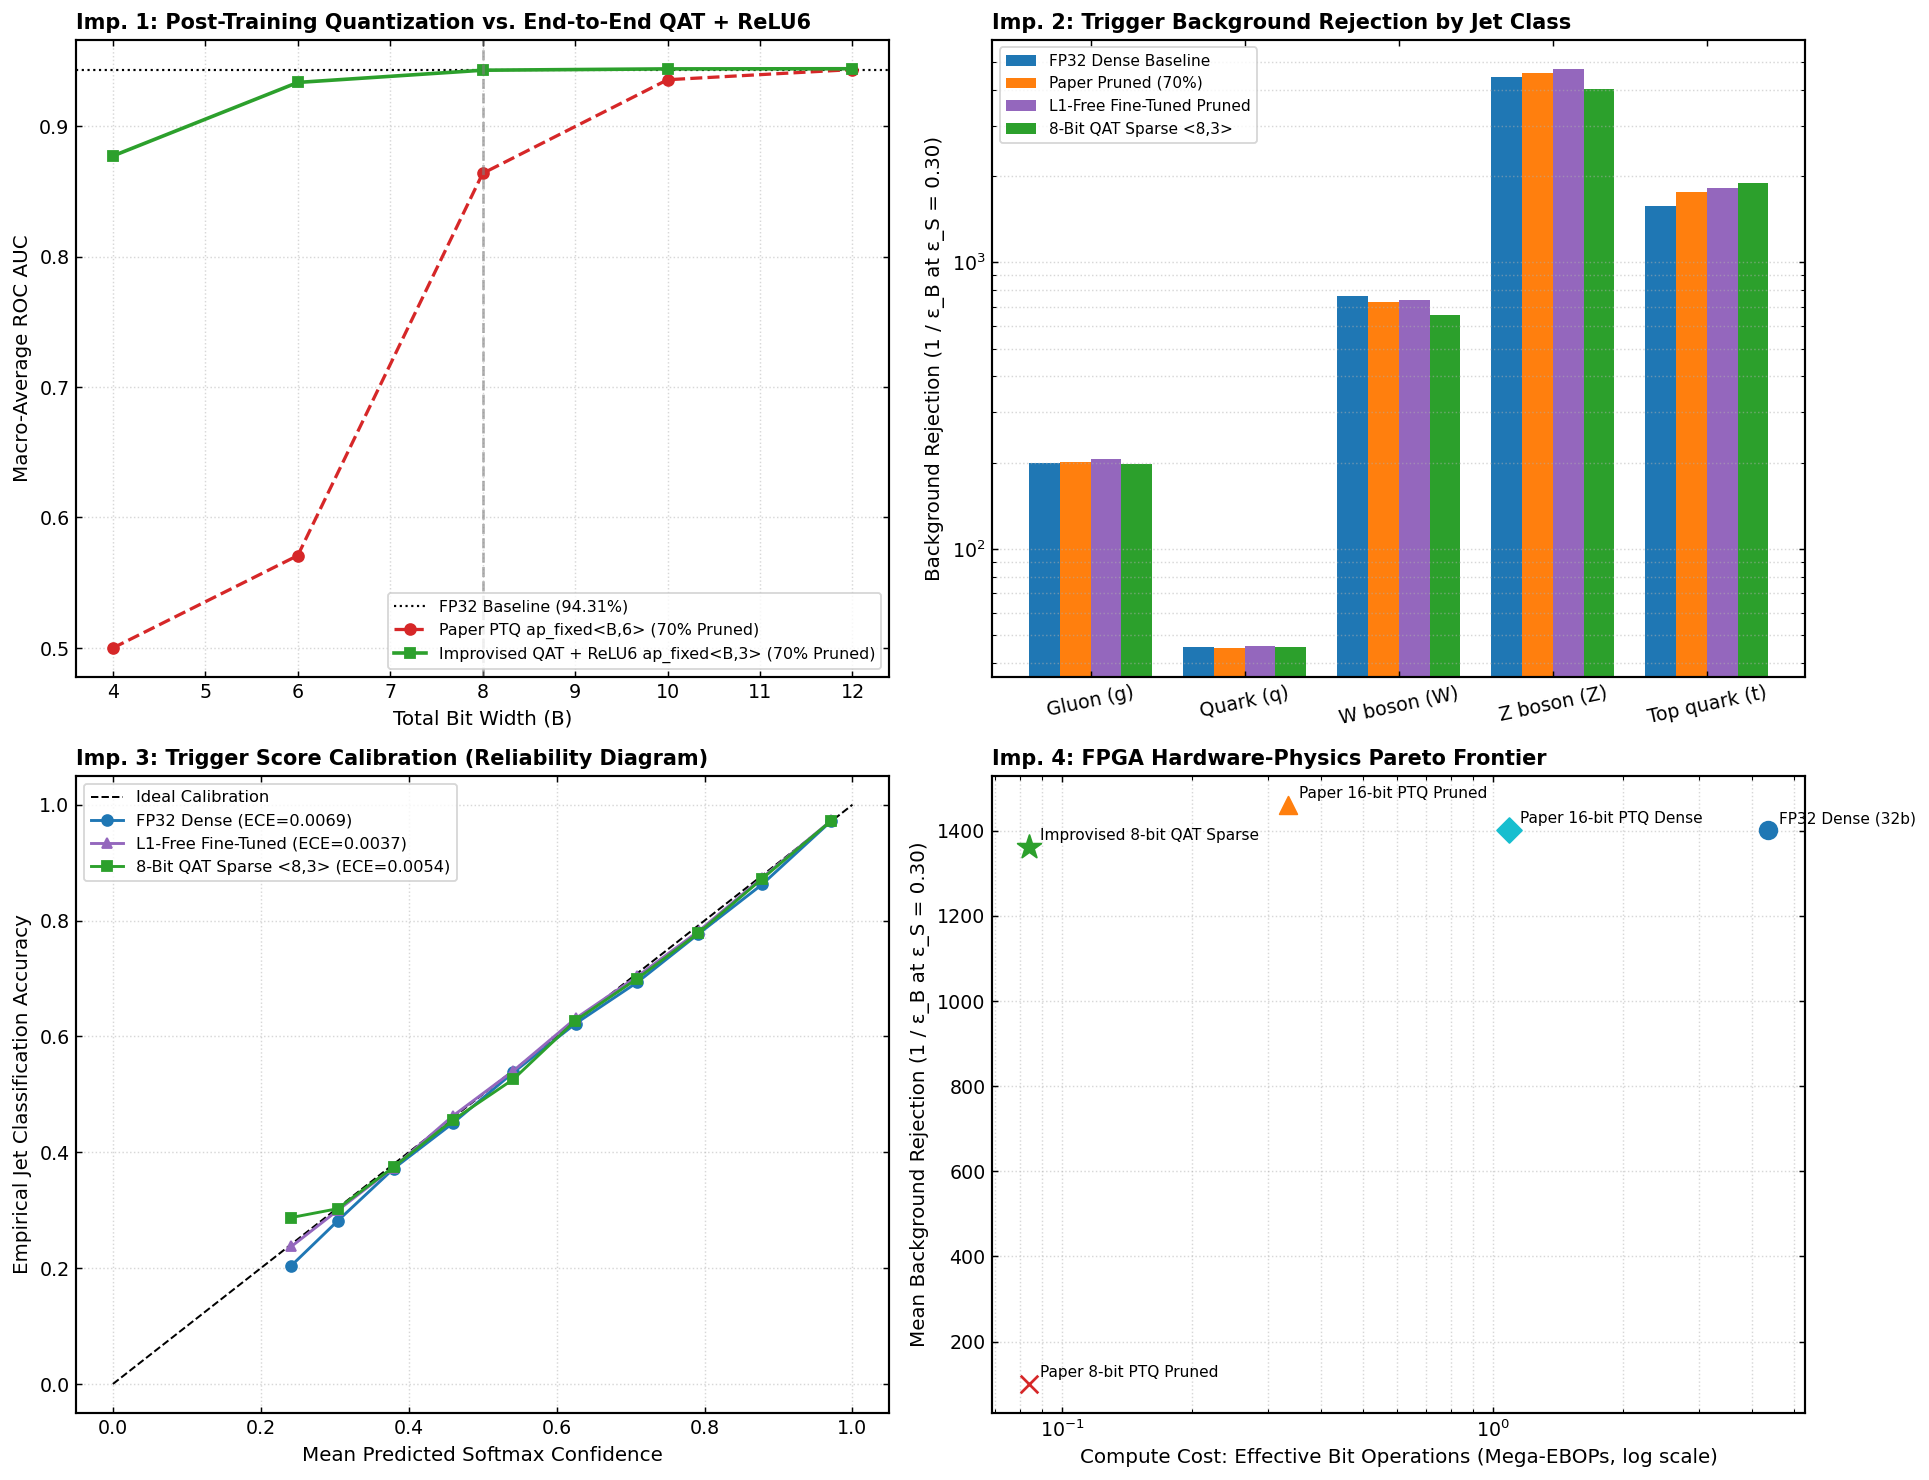

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(15, 11.5))

ax = axes[0, 0]
ax.axhline(fp32_sweep_macro_auc, color='black', linestyle=':', linewidth=1.2,
           label=f'FP32 Baseline ({fp32_sweep_macro_auc*100:.2f}%)')
ax.plot(low_bits, ptq_mean_aucs, 'o--', color='#d62728', linewidth=1.8,
        label='Paper PTQ ap_fixed<B,6> (70% Pruned)')
ax.plot(low_bits, qat_mean_aucs, 's-', color='#2ca02c', linewidth=2.0,
        label='Improvised QAT + ReLU6 ap_fixed<B,3> (70% Pruned)')
ax.axvline(8, color='gray', linestyle='--', alpha=0.6)
ax.set_xlabel('Total Bit Width (B)')
ax.set_ylabel('Macro-Average ROC AUC')
ax.set_title('Imp. 1: Post-Training Quantization vs. End-to-End QAT + ReLU6', loc='left', fontweight='bold')
ax.grid(True, linestyle=':', alpha=0.5)
ax.legend(loc='lower right', frameon=True, fontsize=8.8)

ax = axes[0, 1]
x_pos = np.arange(len(CLASS_LABELS))
w_bar = 0.20
ax.bar(x_pos - 1.5*w_bar, rej_base, width=w_bar, color='#1f77b4', label='FP32 Dense Baseline')
ax.bar(x_pos - 0.5*w_bar, rej_pruned, width=w_bar, color='#ff7f0e', label='Paper Pruned (70%)')
ax.bar(x_pos + 0.5*w_bar, rej_ft, width=w_bar, color='#9467bd', label='L1-Free Fine-Tuned Pruned')
ax.bar(x_pos + 1.5*w_bar, rej_qat8, width=w_bar, color='#2ca02c', label='8-Bit QAT Sparse <8,3>')
ax.set_yscale('log')
ax.set_xticks(x_pos)
ax.set_xticklabels([CLASS_DISPLAY[c] for c in CLASS_LABELS], rotation=12)
ax.set_ylabel('Background Rejection (1 / ε_B at ε_S = 0.30)')
ax.set_title('Imp. 2: Trigger Background Rejection by Jet Class', loc='left', fontweight='bold')
ax.grid(True, which='both', axis='y', linestyle=':', alpha=0.5)
ax.legend(loc='upper left', frameon=True, fontsize=8.5)

ax = axes[1, 0]
ax.plot([0, 1], [0, 1], 'k--', linewidth=1.1, label='Ideal Calibration')
for lbl, preds, col, sty in [
    ('FP32 Dense', y_pred_base, '#1f77b4', 'o-'),
    ('L1-Free Fine-Tuned', y_pred_ft, '#9467bd', '^-'),
    ('8-Bit QAT Sparse <8,3>', y_pred_qat8, '#2ca02c', 's-')
]:
    confs, accs, ece = compute_calibration_curve(y_test_int, preds)
    ax.plot(confs, accs, sty, color=col, linewidth=1.6, label=f"{lbl} (ECE={ece:.4f})")

ax.set_xlabel('Mean Predicted Softmax Confidence')
ax.set_ylabel('Empirical Jet Classification Accuracy')
ax.set_title('Imp. 3: Trigger Score Calibration (Reliability Diagram)', loc='left', fontweight='bold')
ax.grid(True, linestyle=':', alpha=0.5)
ax.legend(loc='upper left', frameon=True, fontsize=9)

ax = axes[1, 1]
pareto_points = [
    ('FP32 Dense (32b)', total_macs * 32 * 32 / 1e6, np.mean(rej_base), '#1f77b4', 'o'),
    ('Paper 16-bit PTQ Dense', total_macs * 16 * 16 / 1e6, np.mean(rej_ptq16_dense), '#17becf', 'D'),
    ('Paper 16-bit PTQ Pruned', nonzero_macs * 16 * 16 / 1e6, np.mean(rej_ptq16_pruned), '#ff7f0e', '^'),
    ('Paper 8-bit PTQ Pruned', nonzero_macs * 8 * 8 / 1e6, np.mean(rej_ptq8_pruned), '#d62728', 'x'),
    ('Improvised 8-bit QAT Sparse', nonzero_macs * 8 * 8 / 1e6, np.mean(rej_qat8), '#2ca02c', '*')
]

for name, ebops_m, mean_rej, col, marker in pareto_points:
    sz = 190 if marker == '*' else 95
    ax.scatter(ebops_m, mean_rej, color=col, marker=marker, s=sz, zorder=5)
    ax.annotate(name, (ebops_m, mean_rej), textcoords="offset points", xytext=(6, 4), fontsize=8.5)

ax.set_xscale('log')
ax.set_xlabel('Compute Cost: Effective Bit Operations (Mega-EBOPs, log scale)')
ax.set_ylabel('Mean Background Rejection (1 / ε_B at ε_S = 0.30)')
ax.set_title('Imp. 4: FPGA Hardware-Physics Pareto Frontier', loc='left', fontweight='bold')
ax.grid(True, which='both', linestyle=':', alpha=0.5)

plt.tight_layout()
plt.savefig('improvisation_diagnostics.png', bbox_inches='tight')
plt.show()

In [ ]:
# Benchmark Table
macro_auc_ft = np.mean([auc(*roc_curve(y_test[:, c], y_pred_ft[:, c])[:2]) for c in range(5)])
macro_auc_qat8 = np.mean([auc(*roc_curve(y_test[:, c], y_pred_qat8[:, c])[:2]) for c in range(5)])
macro_auc_ptq8 = np.mean([auc(*roc_curve(y_test[:, c], y_pred_ptq8_pruned[:, c])[:2]) for c in range(5)])
macro_auc_ptq16 = np.mean([auc(*roc_curve(y_test[:, c], y_pred_ptq16_pruned[:, c])[:2]) for c in range(5)])

summary_df = pd.DataFrame([
    {
        'Model Variant': '1. Paper Dense Baseline (FP32)',
        'Test Acc (%)': round(acc_base * 100, 2),
        'Macro AUC (%)': round(np.mean(fp32_aucs_base) * 100, 2),
        'Mean 1/ε_B @ ε_S=0.3': round(np.mean(rej_base), 1),
        'Nonzero MACs': total_macs,
        'KU115 DSPs (R=1)': total_macs * hls_dsp_per_mult(32),
        'Precision': 'FP32 (32b)',
        'EBOPs (kOps)': round(total_macs * 32 * 32 / 1e3, 1)
    },
    {
        'Model Variant': '2. Paper 16-Bit PTQ Pruned (70%)',
        'Test Acc (%)': round(accuracy_score(y_test_int, np.argmax(y_pred_ptq16_pruned, axis=1)) * 100, 2),
        'Macro AUC (%)': round(macro_auc_ptq16 * 100, 2),
        'Mean 1/ε_B @ ε_S=0.3': round(np.mean(rej_ptq16_pruned), 1),
        'Nonzero MACs': nonzero_macs,
        'KU115 DSPs (R=1)': nonzero_macs * hls_dsp_per_mult(16),
        'Precision': 'ap_fixed<16,6>',
        'EBOPs (kOps)': round(nonzero_macs * 16 * 16 / 1e3, 1)
    },
    {
        'Model Variant': '3. Paper 8-Bit PTQ Pruned (70%)',
        'Test Acc (%)': round(accuracy_score(y_test_int, np.argmax(y_pred_ptq8_pruned, axis=1)) * 100, 2),
        'Macro AUC (%)': round(macro_auc_ptq8 * 100, 2),
        'Mean 1/ε_B @ ε_S=0.3': round(np.mean(rej_ptq8_pruned), 1),
        'Nonzero MACs': nonzero_macs,
        'KU115 DSPs (R=1)': nonzero_macs * hls_dsp_per_mult(8),
        'Precision': 'ap_fixed<8,6>',
        'EBOPs (kOps)': round(nonzero_macs * 8 * 8 / 1e3, 1)
    },
    {
        'Model Variant': '4. Imp: L1-Free Fine-Tuned Pruned',
        'Test Acc (%)': round(acc_ft * 100, 2),
        'Macro AUC (%)': round(macro_auc_ft * 100, 2),
        'Mean 1/ε_B @ ε_S=0.3': round(np.mean(rej_ft), 1),
        'Nonzero MACs': nonzero_macs,
        'KU115 DSPs (R=1)': nonzero_macs * hls_dsp_per_mult(32),
        'Precision': 'FP32 (32b)',
        'EBOPs (kOps)': round(nonzero_macs * 32 * 32 / 1e3, 1)
    },
    {
        'Model Variant': '5. Imp: 8-Bit QAT Sparse ReLU6',
        'Test Acc (%)': round(acc_qat8 * 100, 2),
        'Macro AUC (%)': round(macro_auc_qat8 * 100, 2),
        'Mean 1/ε_B @ ε_S=0.3': round(np.mean(rej_qat8), 1),
        'Nonzero MACs': nonzero_macs,
        'KU115 DSPs (R=1)': nonzero_macs * hls_dsp_per_mult(8),
        'Precision': 'ap_fixed<8,3>',
        'EBOPs (kOps)': round(nonzero_macs * 8 * 8 / 1e3, 1)
    }
])

print("\n=== BENCHMARK COMPARISON: PAPER REPLICATION VS. IMPROVISATIONS ===")
print(summary_df.to_string(index=False))


=== BENCHMARK COMPARISON: PAPER REPLICATION VS. IMPROVISATIONS ===
                    Model Variant  Test Acc (%)  Macro AUC (%)  Mean 1/ε_B @ ε_S=0.3  Nonzero MACs  KU115 DSPs (R=1)      Precision  EBOPs (kOps)
   1. Paper Dense Baseline (FP32)         76.71          94.32                1400.9          4256             17024     FP32 (32b)        4358.1
 2. Paper 16-Bit PTQ Pruned (70%)         76.86          94.38                1460.9          1309              1309 ap_fixed<16,6>         335.1
  3. Paper 8-Bit PTQ Pruned (70%)         59.88          86.48                 100.2          1309                 0  ap_fixed<8,6>          83.8
4. Imp: L1-Free Fine-Tuned Pruned         76.94          94.41                1507.9          1309              5236     FP32 (32b)        1340.4
   5. Imp: 8-Bit QAT Sparse ReLU6         76.76          94.29                1361.4          1309                 0  ap_fixed<8,3>          83.8


In [ ]:
train_tq_mask = np.isin(y_train_int, [0, 1, 4])
val_tq_mask   = np.isin(y_val_int,   [0, 1, 4])
test_tq_mask  = np.isin(y_test_int,  [0, 1, 4])

X_train_1l, y_train_1l = X_train[train_tq_mask], (y_train_int[train_tq_mask] == 4).astype(np.float32)
X_val_1l,   y_val_1l   = X_val[val_tq_mask],     (y_val_int[val_tq_mask] == 4).astype(np.float32)
X_test_1l,  y_test_1l  = X_test[test_tq_mask],   (y_test_int[test_tq_mask] == 4).astype(np.float32)

def build_1layer_top_tagger(l1_reg=1e-4):
    reg = tf.keras.regularizers.l1(l1_reg) if l1_reg else None
    inp = Input(shape=(16,), name='input_1l')
    h1  = Dense(32, activation='relu', kernel_regularizer=reg, name='fc1_1l')(inp)
    out = Dense(1, activation='sigmoid', kernel_regularizer=reg, name='out_1l')(h1)
    return Model(inp, out, name='hls4ml_1layer_top_tagger')

model_1l = build_1layer_top_tagger(l1_reg=1e-4)
model_1l.compile(optimizer=Adam(learning_rate=1e-3), loss='binary_crossentropy', metrics=['accuracy'])
model_1l.fit(
    X_train_1l, y_train_1l,
    validation_data=(X_val_1l, y_val_1l),
    epochs=40, batch_size=1024,
    callbacks=[EarlyStopping(monitor='val_loss', patience=8, restore_best_weights=True)],
    verbose=0
)

LAYER_NAMES_1L = ['fc1_1l', 'out_1l']
pruned_1l = clone_model(model_1l)
pruned_1l.set_weights(model_1l.get_weights())
pruned_1l.compile(optimizer=Adam(learning_rate=5e-4), loss='binary_crossentropy')

masks_1l = {}
for step in range(1, 8):
    s_cur = 0.70 * (1.0 - (1.0 - step / 7.0) ** 3)
    if step > 1:
        pruned_1l.fit(X_train_1l, y_train_1l, epochs=6, batch_size=1024,
                      callbacks=[MaskEnforcerCallback(masks_1l)], verbose=0)
    for name in LAYER_NAMES_1L:
        w_list = pruned_1l.get_layer(name).get_weights()
        thresh = np.percentile(np.abs(w_list[0]), s_cur * 100.0)
        m = (np.abs(w_list[0]) > thresh).astype(np.float32)
        w_list[0] = w_list[0] * m
        pruned_1l.get_layer(name).set_weights(w_list)
        masks_1l[name] = m

pruned_1l.fit(X_train_1l, y_train_1l, epochs=8, batch_size=1024,
              callbacks=[MaskEnforcerCallback(masks_1l)], verbose=0)

def eval_1l_fixed(m, X_d, y_d, total_bits=16, int_bits=6):
    h = quantize_ap_fixed(X_d, total_bits, int_bits)
    for idx, name in enumerate(LAYER_NAMES_1L):
        w, b = m.get_layer(name).get_weights()
        wq = quantize_ap_fixed(w, total_bits, int_bits)
        bq = quantize_ap_fixed(b, total_bits, int_bits)
        z  = quantize_ap_fixed(np.dot(h, wq) + bq, total_bits, int_bits)
        if idx == 0:
            h = np.maximum(0.0, z)
        else:
            h = 1.0 / (1.0 + np.exp(-np.clip(z, -16.0, 16.0)))
    fpr, tpr, _ = roc_curve(y_d, h.ravel())
    return auc(fpr, tpr)

auc_1l_fp32   = auc(*roc_curve(y_test_1l, model_1l.predict(X_test_1l, batch_size=4096, verbose=0).ravel())[:2])
auc_1l_dense  = eval_1l_fixed(model_1l,  X_test_1l, y_test_1l, 16, 6)
auc_1l_pruned = eval_1l_fixed(pruned_1l, X_test_1l, y_test_1l, 16, 6)

dense_1l_macs  = sum(int(model_1l.get_layer(n).get_weights()[0].size) for n in LAYER_NAMES_1L)
pruned_1l_macs = sum(int(np.sum(pruned_1l.get_layer(n).get_weights()[0] != 0)) for n in LAYER_NAMES_1L)

table2_df = pd.DataFrame([
    {
        'Benchmark Model': 'Top Tagger 1-Layer (Uncompressed, <16,6>)',
        'AUC / FP32 AUC (%)': round(100.0 * auc_1l_dense / auc_1l_fp32, 2),
        'Total Params': model_1l.count_params(),
        'Nonzero MACs': dense_1l_macs,
        'KU115 DSPs (R=1)': dense_1l_macs * hls_dsp_per_mult(16),
        'Est. Latency (ns @ 200 MHz)': 10 * 5
    },
    {
        'Benchmark Model': 'Top Tagger 1-Layer (70% Compressed, <16,6>)',
        'AUC / FP32 AUC (%)': round(100.0 * auc_1l_pruned / auc_1l_fp32, 2),
        'Total Params': pruned_1l_macs + 33,
        'Nonzero MACs': pruned_1l_macs,
        'KU115 DSPs (R=1)': pruned_1l_macs * hls_dsp_per_mult(16),
        'Est. Latency (ns @ 200 MHz)': 10 * 5
    },
    {
        'Benchmark Model': 'Substructure 3-Layer (Uncompressed, <16,6>)',
        'AUC / FP32 AUC (%)': round(100.0 * np.mean([auc(*roc_curve(y_test[:, c], y_pred_ptq16_dense[:, c])[:2]) for c in range(5)]) / np.mean(fp32_aucs_base), 2),
        'Total Params': baseline_model.count_params(),
        'Nonzero MACs': total_macs,
        'KU115 DSPs (R=1)': total_macs * hls_dsp_per_mult(16),
        'Est. Latency (ns @ 200 MHz)': 15 * 5
    },
    {
        'Benchmark Model': 'Substructure 3-Layer (70% Compressed, <16,6>)',
        'AUC / FP32 AUC (%)': round(100.0 * macro_auc_ptq16 / np.mean(fp32_aucs_pruned), 2),
        'Total Params': nonzero_macs + 133,
        'Nonzero MACs': nonzero_macs,
        'KU115 DSPs (R=1)': nonzero_macs * hls_dsp_per_mult(16),
        'Est. Latency (ns @ 200 MHz)': 15 * 5
    }
])
print("\n=== TABLE 2 REPLICATION: 1-LAYER TOP TAGGER VS. 3-LAYER SUBSTRUCTURE MODEL ===")
print(table2_df.to_string(index=False))


=== TABLE 2 REPLICATION: 1-LAYER TOP TAGGER VS. 3-LAYER SUBSTRUCTURE MODEL ===
                              Benchmark Model  AUC / FP32 AUC (%)  Total Params  Nonzero MACs  KU115 DSPs (R=1)  Est. Latency (ns @ 200 MHz)
    Top Tagger 1-Layer (Uncompressed, <16,6>)              100.00           577           544               544                           50
  Top Tagger 1-Layer (70% Compressed, <16,6>)               99.91           197           164               164                           50
  Substructure 3-Layer (Uncompressed, <16,6>)              100.00          4389          4256              4256                           75
Substructure 3-Layer (70% Compressed, <16,6>)              100.00          1442          1309              1309                           75


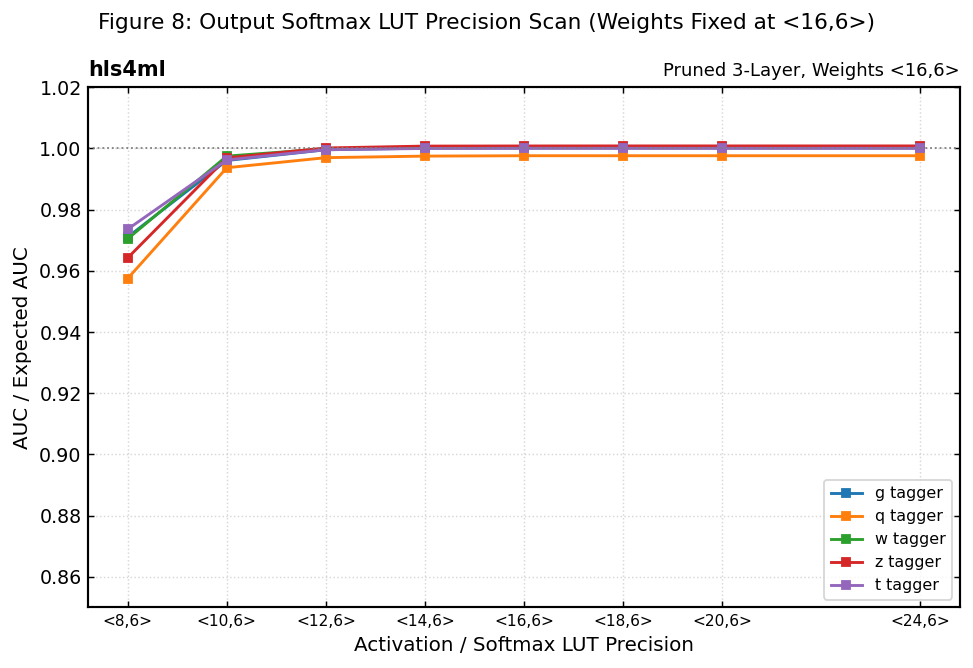

In [ ]:
def evaluate_softmax_lut_precision(model, X_data, y_true_onehot, act_bits, act_int_bits=6):
    """Weights/biases fixed at <16,6>; scans Softmax LUT output precision <act_bits, 6>."""
    h = quantize_ap_fixed(X_data, 16, 6)
    for idx, name in enumerate(LAYER_NAMES):
        w, b = model.get_layer(name).get_weights()
        wq = quantize_ap_fixed(w, 16, 6)
        bq = quantize_ap_fixed(b, 16, 6)
        z  = quantize_ap_fixed(np.dot(h, wq) + bq, 16, 6)
        if idx < len(LAYER_NAMES) - 1:
            h = quantize_ap_fixed(np.maximum(0.0, z), act_bits, act_int_bits)
        else:
            z_shift = z - np.max(z, axis=1, keepdims=True)
            exp_lut = quantize_ap_fixed(np.exp(z_shift), act_bits, act_int_bits)
            denom   = np.maximum(np.sum(exp_lut, axis=1, keepdims=True), 2.0 ** (-(act_bits - act_int_bits)))
            h       = exp_lut / denom
    return np.array([auc(*roc_curve(y_true_onehot[:, c], h[:, c])[:2]) for c in range(5)])

act_bits_scan = [8, 10, 12, 14, 16, 18, 20, 24]
act_ratios = []
for b_act in act_bits_scan:
    aucs_act = evaluate_softmax_lut_precision(pruned_model, X_test[:50000], y_test[:50000], b_act, 6)
    act_ratios.append(aucs_act / fp32_aucs_pruned)
act_ratios = np.array(act_ratios)

fig, ax8 = plt.subplots(figsize=(7.6, 5.2))
for idx, cls_name in enumerate(CLASS_LABELS):
    ax8.plot(act_bits_scan, act_ratios[:, idx], marker='s', markersize=4,
             color=CLASS_COLORS[cls_name], linewidth=1.6, label=f"{cls_name} tagger")

ax8.axhline(1.0, color='gray', linestyle=':', linewidth=1.0)
ax8.set_ylim(0.85, 1.02)
ax8.set_xticks(act_bits_scan)
ax8.set_xticklabels([f"<{b},6>" for b in act_bits_scan], fontsize=8.5)
ax8.set_xlabel('Activation / Softmax LUT Precision')
ax8.set_ylabel('AUC / Expected AUC')
ax8.set_title('hls4ml', loc='left', fontweight='bold')
ax8.set_title('Pruned 3-Layer, Weights <16,6>', loc='right', fontsize=10)
ax8.grid(True, linestyle=':', alpha=0.5)
ax8.legend(loc='lower right', frameon=True, fontsize=8.8)
fig.suptitle('Figure 8: Output Softmax LUT Precision Scan (Weights Fixed at <16,6>)', fontsize=12)
plt.tight_layout()
plt.savefig('fig8_softmax_lut_precision.png', bbox_inches='tight')
plt.show()

In [ ]:
# Real hls4ml C++ Firmware and bit-exact C-Simulation
!pip install -q "hls4ml[keras-v3]"

import os
import sys
import shutil
import importlib
import numpy as np
import torch
import torch.nn as nn
from sklearn.metrics import accuracy_score, roc_curve, auc

for mod_name in list(sys.modules.keys()):
    if mod_name == 'hls4ml' or mod_name.startswith('hls4ml.'):
        del sys.modules[mod_name]
importlib.invalidate_caches()

import quantizers
if not hasattr(quantizers, 'get_fixed_quantizer_np'):
    quantizers.get_fixed_quantizer_np = lambda *args, **kwargs: None

import hls4ml
import hls4ml.utils
import hls4ml.converters

OUT_DIR = os.path.abspath('hls4ml_prj_3layer_pruned')
shutil.rmtree(OUT_DIR, ignore_errors=True)

pt_model = nn.Sequential(
    nn.Linear(16, 64),
    nn.ReLU(),
    nn.Linear(64, 32),
    nn.ReLU(),
    nn.Linear(32, 32),
    nn.ReLU(),
    nn.Linear(32, 5),
    nn.Softmax(dim=-1)
).eval()

src_names = ['fc1_relu', 'fc2_relu', 'fc3_relu', 'output_softmax']
with torch.no_grad():
    for pt_idx, s_name in zip([0, 2, 4, 6], src_names):
        w_np, b_np = ft_pruned_model.get_layer(s_name).get_weights()
        pt_model[pt_idx].weight.copy_(torch.from_numpy(w_np.T.copy()))
        pt_model[pt_idx].bias.copy_(torch.from_numpy(b_np.copy()))

hls_config = hls4ml.utils.config_from_pytorch_model(
    pt_model,
    input_shape=(16,),
    granularity='model',
    default_precision='ap_fixed<16,6>',
    default_reuse_factor=1
)
hls_config['Model']['Strategy'] = 'Latency'

hls_model = hls4ml.converters.convert_from_pytorch_model(
    pt_model,
    hls_config=hls_config,
    output_dir=OUT_DIR,
    part='xcku115-flvb2104-2-i'
)
hls_model.write()

X_sim = np.ascontiguousarray(X_test[:10000], dtype=np.float32)
orig_cwd = os.getcwd()
try:
    os.chdir(OUT_DIR)
    hls_model.compile()
    y_hls_pred = hls_model.predict(X_sim)
finally:
    os.chdir(orig_cwd)

_, y_py_sim = evaluate_fixed_point_model(ft_pruned_model, X_sim, y_test[:10000], 16, 6)

acc_hls  = accuracy_score(y_test_int[:10000], np.argmax(y_hls_pred, axis=1))
auc_hls  = np.mean([auc(*roc_curve(y_test[:10000, c], y_hls_pred[:, c])[:2]) for c in range(5)])
max_diff = np.max(np.abs(y_hls_pred - y_py_sim))

print("=== REAL hls4ml C++ FIRMWARE C-SIMULATION VERIFICATION (KU115) ===")
print(f"Generated Firmware Dir : ./hls4ml_prj_3layer_pruned/firmware/")
print(f"Sample 0 C++ Output    : {np.round(y_hls_pred[0], 4)}")
print(f"Sample 0 Python Output : {np.round(y_py_sim[0], 4)}")
print(f"hls4ml C-Sim Accuracy  : {acc_hls * 100:.2f}%")
print(f"hls4ml C-Sim Macro AUC : {auc_hls * 100:.2f}%")
print(f"Max |hls4ml - Python|  : {max_diff:.6f}")

if shutil.which('vivado_hls') or shutil.which('vitis_hls'):
    print("Vivado/Vitis HLS detected! Running RTL C-synthesis...")
    hls_model.build(csim=False, synth=True)
    hls4ml.report.read_vivado_report(OUT_DIR)
else:
    print("Note: Vivado/Vitis HLS CLI not in PATH — C++ firmware & bit-exact C-sim completed; RTL synthesis skipped.")

Interpreting Model ...
Topology:
Layer name: _0, layer type: Dense, input shape: [[None, 16]]
Layer name: _1, layer type: Activation, input shape: [[None, 64]]
Layer name: _2, layer type: Dense, input shape: [[None, 64]]
Layer name: _3, layer type: Activation, input shape: [[None, 32]]
Layer name: _4, layer type: Dense, input shape: [[None, 32]]
Layer name: _5, layer type: Activation, input shape: [[None, 32]]
Layer name: _6, layer type: Dense, input shape: [[None, 32]]
Layer name: _7, layer type: Softmax, input shape: [[None, 5]]
=== REAL hls4ml C++ FIRMWARE C-SIMULATION VERIFICATION (KU115) ===
Generated Firmware Dir : ./hls4ml_prj_3layer_pruned/firmware/
Sample 0 C++ Output    : [0.002  0.0107 1.     0.0088 0.0439]
Sample 0 Python Output : [0.0016 0.011  0.938  0.0082 0.0412]
hls4ml C-Sim Accuracy  : 76.99%
hls4ml C-Sim Macro AUC : 94.26%
Max |hls4ml - Python|  : 0.204727
Note: Vivado/Vitis HLS CLI not in PATH — C++ firmware & bit-exact C-sim completed; RTL synthesis skipped.
